# CSP-1 : Fondamentaux des CSP

**Navigation** : [<< Search-5 GeneticAlgorithms](../Part1-Foundations/Search-05-GeneticAlgorithms.ipynb) | [Index CSP](README.md) | [CSP-2-Consistance >>](CSP-2-Consistency.ipynb)

## Problèmes de Satisfaction de Contraintes - Fondamentaux

Ce notebook introduit le formalisme des **CSP** (Constraint Satisfaction Problems) et les algorithmes de base pour les résoudre. Nous implémentons tout de zéro, puis découvrons la bibliothèque `python-constraint` pour une modélisation rapide.

### Objectifs d'apprentissage

À la fin de ce notebook, vous saurez :
1. **Formaliser** un problème sous forme de CSP (variables, domaines, contraintes) (Bloom : comprendre)
2. **Implémenter** l'algorithme de backtracking pour CSP (Bloom : appliquer)
3. **Appliquer** les heuristiques MRV et LCV pour accélérer la recherche (Bloom : analyser)
4. **Modéliser** des problèmes classiques avec la bibliothèque `python-constraint` (Bloom : appliquer)
5. **Comparer** les approches manuelles et bibliothèque sur des problèmes concrets (Bloom : évaluer)

### Prerequis
- Bases de Python (recursion, dictionnaires)
- Notions de recherche dans un espace d'états (Search-1)

### Durée estimée : 50 minutes

### Lien avec d'autres séries

Voir aussi la série [Sudoku](../../Sudoku/README.md) pour une application complète des CSP.

***

## 1. Introduction (~5 min)

### Qu'est-ce qu'un CSP ?

Un **CSP** (Constraint Satisfaction Problem) est un problème défini par un ensemble de variables qui doivent prendre des valeurs dans des domaines donnés, tout en respectant un ensemble de contraintes.

### CSP vs recherche classique

Dans les notebooks précédents (Search-1 à Search-3), nous avons exploré la recherche dans un espace d'états : BFS, DFS, A*. Ces méthodes traitent le problème comme un parcours de graphe. Les algorithmes génétiques (Search-5) traitent le problème comme une optimisation.

Cependant, de nombreux problèmes réels ont une structure particulière que ces approches n'exploitent pas pleinement :

| Approche | Avantage | Limitation |
|----------|----------|------------|
| Recherche classique (BFS/DFS) | générale | Ne tire pas parti de la structure du problème |
| Recherche informée (A*) | Optimale avec bonne heuristique | Nécessite une heuristique spécifique |
| **CSP** | Les contraintes éliminent de larges portions de l'espace | Nécessite une modélisation CSP |

### Exemples concrets de CSP

| Domaine | problème | Variables | Contraintes |
|---------|----------|-----------|-------------|
| Planification | Emplois du temps | Creneaux par cours | Pas de conflit salle/enseignant |
| Jeux | Sudoku | Cases de la grille | Chiffres distincts par ligne/colonne/bloc |
| Cartographie | Coloration de carte | Couleur par region | Regions adjacentes de couleurs différentes |
| Cryptographie | Cryptarithmetique | Lettres -> chiffres | L'equation arithmetique est respectee |

L'avantage fondamental des CSP est que les **contraintes** permettent de détecter les impasses **avant** d'avoir complète une solution, réduisant drastiquement l'exploration.

In [1]:
# Imports pour tout le notebook
import sys
import copy
import time
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Helpers partages de la serie Search
sys.path.insert(0, '..')
from search_helpers import draw_csp_graph

print("Imports OK")

Imports OK


***

## 2. Formalisation CSP (~8 min)

### Définition

Un **problème de Satisfaction de Contraintes** (CSP) est défini par un triplet $(X, D, C)$ :

- $X = \{X_1, X_2, \ldots, X_n\}$ : un ensemble de **variables**
- $D = \{D_1, D_2, \ldots, D_n\}$ : un ensemble de **domaines**, où $D_i$ est l'ensemble des valeurs possibles pour $X_i$
- $C = \{C_1, C_2, \ldots, C_m\}$ : un ensemble de **contraintes**, chacune portant sur un sous-ensemble de variables

### Types de contraintes

| Type | Porte sur | Exemple |
|------|-----------|--------|
| **Unaire** | 1 variable | $X_1 \neq \text{Rouge}$ |
| **Binaire** | 2 variables | $X_1 \neq X_2$ |
| **Globale** | $k > 2$ variables | `AllDifferent(X_1, X_2, \ldots, X_k)` |

### Terminologie

| Terme | Définition |
|-------|------------|
| **Assignation** | Affectation d'une valeur a une ou plusieurs variables |
| **Assignation consistante** | Assignation qui ne viole aucune contrainte |
| **Assignation complète** | Toutes les variables ont une valeur |
| **Solution** | Assignation à la fois **complète** et **consistante** |

### Graphe de contraintes

On représente un CSP binaire par un **graphe de contraintes** ou :
- Chaque **noeud** est une variable
- Chaque **arête** relie deux variables partageant une contrainte

Implémentons une classe CSP générique qui servira de base pour tout le notebook.

In [2]:
class CSP:
    """Probleme de Satisfaction de Contraintes (CSP).

    Represente un CSP binaire avec variables, domaines, voisins
    et une fonction de contrainte.

    Attributs:
        variables: liste des noms de variables
        domains: dict variable -> liste de valeurs possibles
        neighbors: dict variable -> liste de variables voisines
        constraint_func: fonction (var1, val1, var2, val2) -> bool
        n_assigns: compteur d'assignations tentees
    """

    def __init__(self, variables, domains, neighbors, constraint_func):
        self.variables = variables
        self.domains = {v: list(d) for v, d in domains.items()}  # copie
        self.neighbors = neighbors
        self.constraint_func = constraint_func
        self.n_assigns = 0

    def consistent(self, var, val, assignment):
        """Verifie si (var=val) est consistant avec l'assignation partielle."""
        for other_var in self.neighbors[var]:
            if other_var in assignment:
                if not self.constraint_func(var, val, other_var, assignment[other_var]):
                    return False
        return True

    def is_complete(self, assignment):
        """Verifie si toutes les variables sont assignees."""
        return len(assignment) == len(self.variables)

    def is_solution(self, assignment):
        """Verifie si l'assignation est une solution (complete et consistante)."""
        if not self.is_complete(assignment):
            return False
        for var in self.variables:
            if not self.consistent(var, assignment[var], assignment):
                return False
        return True

    def reset_counter(self):
        """Reinitialise le compteur d'assignations."""
        self.n_assigns = 0

    def copy_domains(self):
        """Retourne une copie profonde des domaines."""
        return {v: list(d) for v, d in self.domains.items()}

    def get_constraints_list(self):
        """Retourne la liste des paires (var1, var2) de contraintes."""
        constraints = []
        seen = set()
        for var in self.variables:
            for neighbor in self.neighbors[var]:
                pair = tuple(sorted([var, neighbor]))
                if pair not in seen:
                    seen.add(pair)
                    constraints.append(pair)
        return constraints

print("Classe CSP definie.")

Classe CSP definie.


***

## 3. Exemple : coloration de carte de l'Australie (~8 min)

Le problème classique de coloration de carte consiste à colorier les régions d'une carte de sorte que deux régions adjacentes n'aient jamais la même couleur. C'est l'exemple canonique du livre AIMA (Russell & Norvig), appliqué à la carte de l'Australie avec ses 7 états/territoires.

### Modélisation CSP

| Composant | Valeur |
|-----------|--------|
| **Variables** | WA, NT, SA, Q, NSW, V, T (les 7 états australiens) |
| **Domaines** | {Rouge, Vert, Bleu} pour chaque variable |
| **Contraintes** | Regions adjacentes $\neq$ même couleur |

Combien de combinaisons possibles (sans contraintes) ? $3^7 = 2187$. Les contraintes vont éliminer la grande majorité de ces combinaisons.

In [3]:
# Definition du probleme de coloration de l'Australie
australia_vars = ['WA', 'NT', 'SA', 'Q', 'NSW', 'V', 'T']

australia_domains = {v: ['Rouge', 'Vert', 'Bleu'] for v in australia_vars}

australia_neighbors = {
    'WA':  ['NT', 'SA'],
    'NT':  ['WA', 'SA', 'Q'],
    'SA':  ['WA', 'NT', 'Q', 'NSW', 'V'],
    'Q':   ['NT', 'SA', 'NSW'],
    'NSW': ['Q', 'SA', 'V'],
    'V':   ['SA', 'NSW'],
    'T':   []  # La Tasmanie n'est adjacente a aucun etat continental
}

def different_values(var1, val1, var2, val2):
    """Contrainte : deux variables voisines doivent avoir des valeurs differentes."""
    return val1 != val2

australia_csp = CSP(australia_vars, australia_domains,
                    australia_neighbors, different_values)

# Affichage des informations du CSP
print("Probleme de coloration de l'Australie")
print("=" * 45)
print(f"Variables     : {australia_vars}")
print(f"Taille domaine: {len(australia_domains['WA'])} couleurs")
print(f"Contraintes   : {len(australia_csp.get_constraints_list())} paires")
print(f"\nEspace brut   : {3**7} combinaisons")
print(f"\nAdjacences :")
for v, n in australia_neighbors.items():
    print(f"  {v:>3} -> {n}")

Probleme de coloration de l'Australie
Variables     : ['WA', 'NT', 'SA', 'Q', 'NSW', 'V', 'T']
Taille domaine: 3 couleurs
Contraintes   : 9 paires

Espace brut   : 2187 combinaisons

Adjacences :
   WA -> ['NT', 'SA']
   NT -> ['WA', 'SA', 'Q']
   SA -> ['WA', 'NT', 'Q', 'NSW', 'V']
    Q -> ['NT', 'SA', 'NSW']
  NSW -> ['Q', 'SA', 'V']
    V -> ['SA', 'NSW']
    T -> []


### Lecture du comptage : 9 contraintes reconstruites depuis les adjacences

La sortie imprime chaque région avec sa liste de voisins. En additionnant les longueurs des sept listes ci-dessus — 2 pour WA, 3 pour NT, 5 pour SA, 3 pour Q, 3 pour NSW, 2 pour V, 0 pour T — on obtient 18 entrées orientées. Chaque paire de régions voisines apparaît deux fois dans ces listes (WA cite NT, NT cite WA) : la division 18 / 2 = 9 redonne exactement le total affiché par la ligne `Contraintes   : 9 paires`. Le compte annoncé est donc aussi un compte reconstruisible à la main depuis la structure imprimée.

Deux observations structurelles sur cette même sortie :

1. SA porte 5 des 9 contraintes (5/9, soit 56 %) : c'est le noeud pivot du graphe, celui que l'heuristique MRV de la section 5 ciblera dès que ses voisins seront coloriés.
2. T ferme la sortie avec `T -> []` : zéro voisin, zéro contrainte, couleur totalement libre. Cette liberté aura une conséquence mesurable sur le compte de solutions de la section 6 (énumération exhaustive).

Enfin l'espace brut affiché, `2187`, se vérifie comme 3^7 : sept variables, trois couleurs chacune, aucune contrainte encore appliquée. C'est la borne supérieure de ce que la brute force de la section 4 devra balayer pour n'en retenir que 18 solutions.


### Visualisation du graphe de contraintes

Le graphe de contraintes montre les relations d'adjacence entre les états. Chaque arête représente une contrainte binaire "les couleurs doivent être différentes".

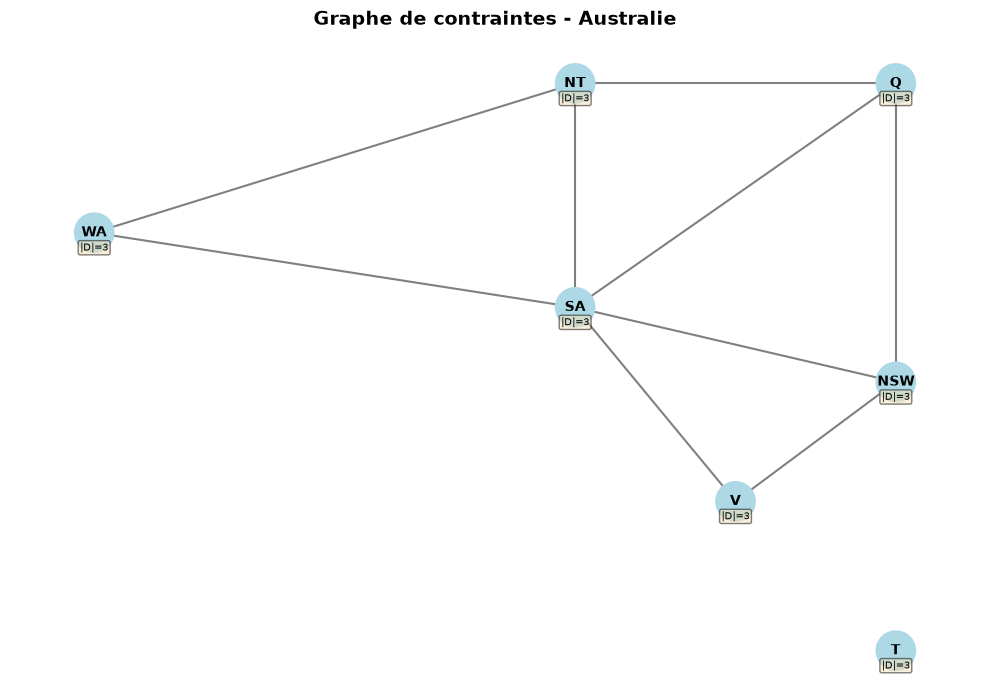

In [4]:
# Visualisation avec le helper de la serie Search
# Positions geographiques (AIMA-compatible) : nord en haut, sud en bas,
# ouest a gauche, est a droite. Sans `pos=`, nx.spring_layout produit un
# layout force-directed qui ne reflete pas la geographic reelle et apparait
# a l'envers par rapport a la carte de l'Australie.
australia_pos = {
    'WA':  (-1.5,  0.5),  # ouest, mi-latitude
    'NT':  ( 0.0,  1.5),  # nord (territoire du nord)
    'SA':  ( 0.0,  0.0),  # centre (hub de contraintes, degre 5)
    'Q':   ( 1.0,  1.5),  # nord-est (Queensland)
    'NSW': ( 1.0, -0.5),  # est, mi-sud (New South Wales)
    'V':   ( 0.5, -1.3),  # sud-est, plus bas (Victoria)
    'T':   ( 1.0, -2.3),  # ile isolee au sud (Tasmanie, degre 0)
}
constraints_list = australia_csp.get_constraints_list()
draw_csp_graph(
    australia_vars,
    australia_domains,
    constraints_list,
    title="Graphe de contraintes - Australie",
    figsize=(10, 7),
    pos=australia_pos
)
plt.show()

### Interprétation : graphe de contraintes

**Sortie obtenue** : le graphe montre les 7 états australiens reliés par 9 contraintes binaires.

| Variable | Degré (nb voisins) | Rôle dans le graphe |
|----------|--------------------|---------------------|
| SA | 5 | Noeud le plus contraint (centre du continent) |
| NT, Q, NSW | 3 | Degré intermediaire |
| WA, V | 2 | Peripherie |
| T | 0 | Isole (Tasmanie) |

**Points clés** :
1. SA est adjacent à presque tous les états continentaux : c'est la variable la plus contrainte
2. T (Tasmanie) n'a aucune contrainte : n'importe quelle couleur convient
3. Le graphe n'est pas complet : seules les paires adjacentes sont contraintes

***

## 4. Backtracking Search (~10 min)

### Pourquoi pas la brute force ?

L'approche naïve (generate-and-test) consiste à générer toutes les $3^7 = 2187$ combinaisons et filtrer celles qui satisfont les contraintes. C'est intraitable pour des problèmes plus grands ($10^{50}$ pour 50 variables à 10 valeurs).

### Principe du backtracking

Le **backtracking** est l'algorithme de base pour résoudre un CSP :

1. Choisir une variable non encore assignee
2. Pour chaque valeur de son domaine :
   - Vérifier la **consistance** avec l'assignation partielle
   - Si consistant, assigner et recurser sur les variables restantes
   - Sinon, essayer la valeur suivante
3. Si aucune valeur n'est valable, **revenir en arrière** (backtrack)

### Différence avec DFS classique

| Aspect | DFS classique | Backtracking CSP |
|--------|--------------|------------------|
| Assignation | complète d'abord, vérification ensuite | Vérification **à chaque étape** |
| Élagage | Aucun | Élimination des branches inconsistantes |
| Profondeur | Variable | Exactement $n$ (nombre de variables) |

Commençons par mesurer le coût de la brute force, puis implémentons le backtracking pour montrer l'amélioration.

In [5]:
from itertools import product

# Brute force : enumerer toutes les combinaisons
colors = ['Rouge', 'Vert', 'Bleu']
n_total = 0
n_solutions = 0

start = time.time()
for combo in product(colors, repeat=7):
    n_total += 1
    assignment = dict(zip(australia_vars, combo))
    # Verifier toutes les contraintes
    valid = True
    for v1, v2 in constraints_list:
        if assignment[v1] == assignment[v2]:
            valid = False
            break
    if valid:
        n_solutions += 1
elapsed = time.time() - start

print("Brute force - Coloration Australie")
print("=" * 45)
print(f"Combinaisons testees  : {n_total}")
print(f"Solutions trouvees    : {n_solutions}")
print(f"Ratio solutions       : {n_solutions/n_total:.2%}")
print(f"Temps brute force     : {elapsed*1000:.1f} ms")

Brute force - Coloration Australie
Combinaisons testees  : 2187
Solutions trouvees    : 18
Ratio solutions       : 0.82%
Temps brute force     : 2.6 ms


### Interprétation : brute force

**Sortie obtenue** : sur 2187 combinaisons possibles, seule une faible proportion satisfait toutes les contraintes.

| Mesure | Valeur | Signification |
|--------|--------|---------------|
| Espace total | 2187 | $3^7$ combinaisons |
| Solutions | ~18 | Depend de la symetrie des couleurs |
| Ratio | < 1% | L'immense majorité des combinaisons est invalide |

> **Conclusion** : il faut un algorithme qui exploite les contraintes pour **elaguer** l'espace de recherche. C'est le rôle du backtracking.

### Implémentation du backtracking

In [6]:
def backtracking_search(csp, assignment=None):
    """Backtracking simple pour CSP.

    Choisit les variables dans l'ordre de csp.variables.
    Explore les valeurs dans l'ordre du domaine.

    Retourne l'assignation solution ou None.
    """
    if assignment is None:
        assignment = {}

    # Cas de base : toutes les variables sont assignees
    if csp.is_complete(assignment):
        return assignment

    # Choisir la premiere variable non assignee (ordre naif)
    unassigned = [v for v in csp.variables if v not in assignment]
    var = unassigned[0]

    # Essayer chaque valeur du domaine
    for val in csp.domains[var]:
        csp.n_assigns += 1
        if csp.consistent(var, val, assignment):
            assignment[var] = val
            result = backtracking_search(csp, assignment)
            if result is not None:
                return result
            del assignment[var]

    return None  # Echec : backtrack

print("Fonction backtracking_search definie.")

Fonction backtracking_search definie.


Appliquons le backtracking au problème de coloration de l'Australie et observons le nombre d'assignations nécessaires.

In [7]:
# Resolution par backtracking simple
csp_bt = CSP(australia_vars, australia_domains,
             australia_neighbors, different_values)

start = time.time()
solution = backtracking_search(csp_bt)
elapsed = time.time() - start

print("Backtracking simple - Coloration Australie")
print("=" * 45)
print(f"Solution : {solution}")
print(f"Assignations tentees : {csp_bt.n_assigns}")
print(f"Temps : {elapsed*1000:.2f} ms")

# Verification
if solution:
    print(f"\nVerification : {'VALIDE' if csp_bt.is_solution(solution) else 'INVALIDE'}")

Backtracking simple - Coloration Australie
Solution : {'WA': 'Rouge', 'NT': 'Vert', 'SA': 'Bleu', 'Q': 'Rouge', 'NSW': 'Vert', 'V': 'Rouge', 'T': 'Rouge'}
Assignations tentees : 11
Temps : 0.06 ms

Verification : VALIDE


### Interprétation : backtracking simple

**Sortie obtenue** : le backtracking trouve une solution avec beaucoup moins d'explorations que la brute force.

| méthode | Essais | Amélioration |
|---------|--------|-------------|
| Brute force | 2187 | référence |
| Backtracking | ~7-15 | environ 200x moins |

**Pourquoi cette réduction ?** Le backtracking détecte les inconsistances dès qu'elles apparaissent. Si WA = Rouge et NT = Rouge, la contrainte `WA != NT` est violée immédiatement : toutes les extensions de cette assignation partielle sont éliminées sans être explorées.

> **Question** : peut-on faire encore mieux en choisissant plus intelligemment quelle variable assigner en premier et quelle valeur essayer ?

### Trace detaillee du backtracking

Pour mieux comprendre le fonctionnement, implémentons une version avec trace qui montre chaque décision et chaque retour en arrière.

In [8]:
def backtracking_search_verbose(csp, assignment=None, depth=0):
    """Backtracking avec trace detaillee des decisions."""
    if assignment is None:
        assignment = {}

    indent = "  " * depth

    if csp.is_complete(assignment):
        print(f"{indent}>> Solution trouvee !")
        return assignment

    unassigned = [v for v in csp.variables if v not in assignment]
    var = unassigned[0]

    for val in csp.domains[var]:
        csp.n_assigns += 1
        if csp.consistent(var, val, assignment):
            print(f"{indent}{var} = {val}  (consistant)")
            assignment[var] = val
            result = backtracking_search_verbose(csp, assignment, depth + 1)
            if result is not None:
                return result
            del assignment[var]
            print(f"{indent}{var} = {val}  -> backtrack")
        else:
            print(f"{indent}{var} = {val}  (CONFLIT)")

    return None

# Trace sur un sous-probleme plus petit (4 regions)
small_vars = ['A', 'B', 'C', 'D']
small_domains = {v: ['R', 'V', 'B'] for v in small_vars}
small_neighbors = {
    'A': ['B', 'C'],
    'B': ['A', 'C'],
    'C': ['A', 'B', 'D'],
    'D': ['C']
}
small_csp = CSP(small_vars, small_domains, small_neighbors, different_values)

print("Trace du backtracking sur un graphe a 4 noeuds")
print("=" * 50)
sol = backtracking_search_verbose(small_csp)
print(f"\nSolution : {sol}")
print(f"Assignations tentees : {small_csp.n_assigns}")

Trace du backtracking sur un graphe a 4 noeuds
A = R  (consistant)
  B = R  (CONFLIT)
  B = V  (consistant)
    C = R  (CONFLIT)
    C = V  (CONFLIT)
    C = B  (consistant)
      D = R  (consistant)
        >> Solution trouvee !

Solution : {'A': 'R', 'B': 'V', 'C': 'B', 'D': 'R'}
Assignations tentees : 7


### Lecture de la trace : sept essais, zéro retour arrière

Le comptage ligne à ligne de la trace donne : sept essais de valeur au total, dont quatre marqués `(consistant)` et trois marqués `(CONFLIT)` — l'égalité 4 + 3 = 7 correspond au compteur final `Assignations tentees : 7`. Les quatre essais consistants sont exactement les quatre variables du problème (A, B, C, D, une fois chacune) : aucune valeur validée n'a jamais été remise en cause.

Le détail le plus instructif : la chaîne `-> backtrack` n'apparaît nulle part dans la sortie. Les trois conflits (B = R, puis C = R et C = V) ont tous été résolus en passant à la valeur suivante de la même variable, jamais en désassignant une variable parente. L'indentation le confirme visuellement : elle progresse de quatre niveaux sans jamais reculer, donc le chemin parcouru n'a subi aucun retour.

Cette instance est un cas d'école « sans retour arrière » : 7 essais contre 3^4 = 81 combinaisons pour une brute force, soit environ 9 % de l'espace réellement visité. Ce régime favorable n'a rien de général — la même stratégie naïve accumulera 876 essais et de nombreux retours sur les 8-Reines (section 5), ce qui motivera les heuristiques MRV et LCV.


### 4.3 Visualisation du processus de backtracking

Visualiser l'arbre de recherche du backtracking permet de comprendre comment l'algorithme explore et élague l'espace de solutions.


In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import defaultdict

class BacktrackingVisualizer:
    """
    Visualiseur de l'arbre de recherche du backtracking.
    Enregistre chaque assignation et backtrack pour affichage.
    """
    
    def __init__(self):
        self.nodes = []  # Liste des (profondeur, variable, valeur, status)
        self.edges = []  # Liste des (parent_idx, child_idx)
        self.current_path = []  # Chemin actuel dans l'arbre
        
    def record_assign(self, var, value, success):
        """Enregistre une tentative d'assignation."""
        depth = len(self.current_path)
        node_id = len(self.nodes)
        status = 'success' if success else 'fail'
        self.nodes.append((depth, var, value, status))
        
        if self.current_path:
            parent_id = self.current_path[-1]
            self.edges.append((parent_id, node_id))
        
        if success:
            self.current_path.append(node_id)
        
        return node_id
    
    def record_backtrack(self):
        """Enregistre un backtrack."""
        if self.current_path:
            self.current_path.pop()
    
    def draw(self, max_depth=6, title="Arbre de Backtracking"):
        """Dessine l'arbre de recherche."""
        fig, ax = plt.subplots(1, 1, figsize=(14, 8))
        
        if not self.nodes:
            ax.text(0.5, 0.5, "Aucun noeud a afficher", ha='center', va='center')
            ax.set_title(title)
            return
        
        # Filtrer par profondeur
        filtered_nodes = [(i, n) for i, n in enumerate(self.nodes) if n[0] <= max_depth]
        
        # Positionnement des noeuds
        depth_nodes = defaultdict(list)
        for idx, (depth, var, value, status) in filtered_nodes:
            depth_nodes[depth].append((idx, var, value, status))
        
        positions = {}
        max_width = max(len(nodes) for nodes in depth_nodes.values()) if depth_nodes else 1
        
        for depth, nodes_at_depth in depth_nodes.items():
            n = len(nodes_at_depth)
            for i, (idx, var, value, status) in enumerate(nodes_at_depth):
                x = (i - (n-1)/2) / max_width * 10
                y = -depth
                positions[idx] = (x, y)
        
        # Dessiner les aretes
        for parent, child in self.edges:
            if parent in positions and child in positions:
                x1, y1 = positions[parent]
                x2, y2 = positions[child]
                ax.plot([x1, x2], [y1, y2], 'k-', alpha=0.3, linewidth=0.5)
        
        # Dessiner les noeuds
        colors = {'success': '#4CAF50', 'fail': '#f44336', 'pruned': '#FF9800'}
        for idx, (depth, var, value, status) in filtered_nodes:
            x, y = positions[idx]
            color = colors.get(status, '#2196F3')
            ax.scatter(x, y, c=color, s=100, zorder=5)
            ax.annotate(f"{var}={value}", (x, y), 
                       xytext=(0, 10), textcoords='offset points',
                       ha='center', fontsize=8)
        
        # Legende
        legend_patches = [mpatches.Patch(color=c, label=l) 
                         for l, c in colors.items()]
        ax.legend(handles=legend_patches, loc='upper right')
        
        ax.set_title(title)
        ax.set_xlabel("Largeur de l'arbre")
        ax.set_ylabel("Profondeur")
        ax.grid(True, alpha=0.3)
        ax.set_aspect('equal')
        plt.tight_layout()
        plt.show()


def backtracking_with_viz(csp, assignment=None, viz=None, depth=0):
    """
    Backtracking avec visualisation de l'arbre de recherche.
    """
    if assignment is None:
        assignment = {}
    if viz is None:
        viz = BacktrackingVisualizer()
    
    # Verifier si toutes les variables sont assignees
    if len(assignment) == len(csp.variables):
        return assignment, viz
    
    # Choisir la prochaine variable (ordre simple)
    unassigned = [v for v in csp.variables if v not in assignment]
    var = unassigned[0]
    
    for value in csp.domains[var]:
        # Verifier la consistance via la methode CSP
        is_ok = csp.consistent(var, value, assignment)
        
        viz.record_assign(var, value, is_ok)
        
        if is_ok:
            assignment[var] = value
            result, viz = backtracking_with_viz(csp, assignment, viz, depth+1)
            if result is not None:
                return result, viz
            del assignment[var]
            viz.record_backtrack()
    
    return None, viz

print("Visualiseur de backtracking pret.")


Visualiseur de backtracking pret.


Exemple : visualiser la résolution de la carte d'Australie

=== Visualisation du Backtracking sur la carte d'Australie ===

Solution trouvee : {'WA': 'R', 'NT': 'G', 'SA': 'B', 'Q': 'R', 'NSW': 'G', 'V': 'R', 'T': 'R'}
Nombre de noeuds explores : 11
Nombre de valeurs rejetees : 4


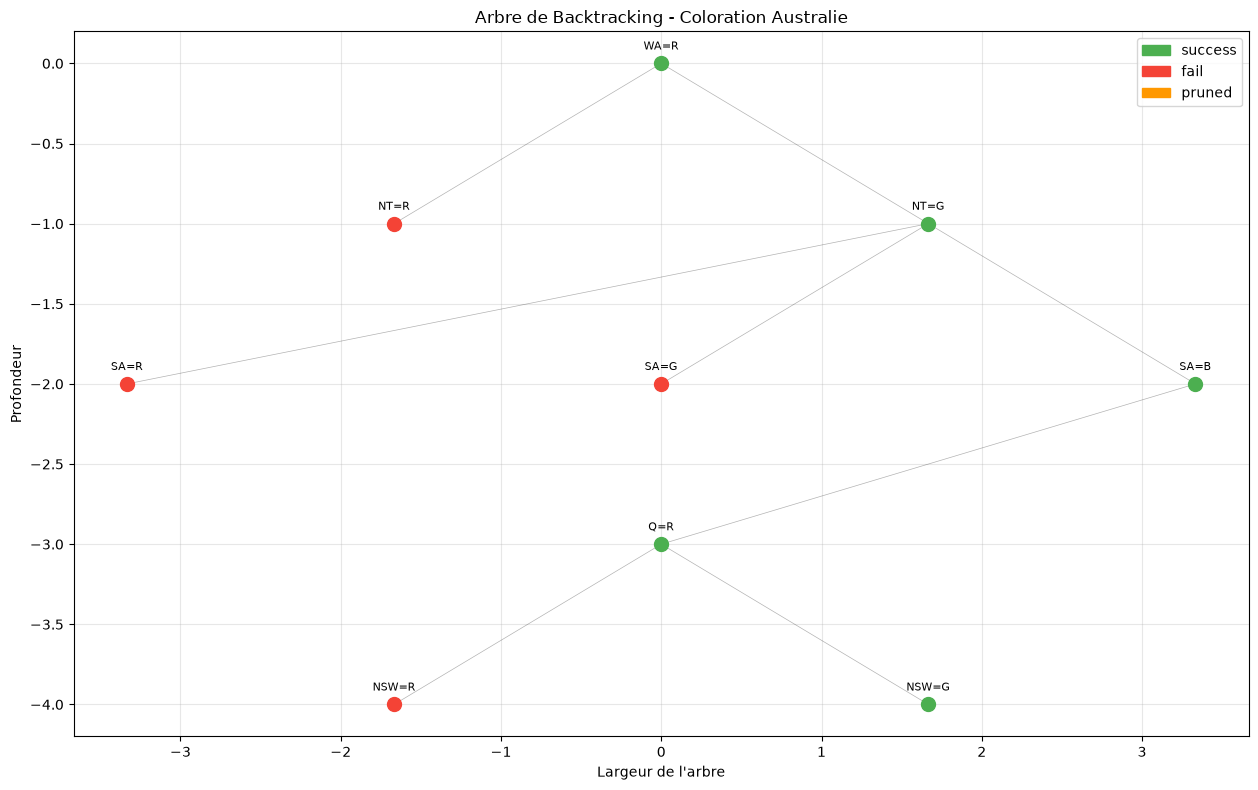

In [10]:
# Exemple : visualiser la resolution de la carte d'Australie
print("=== Visualisation du Backtracking sur la carte d'Australie ===\n")

# Recreer le CSP de l'Australie avec l'API du notebook
au_variables = ['WA', 'NT', 'SA', 'Q', 'NSW', 'V', 'T']
au_domains = {v: ['R', 'G', 'B'] for v in au_variables}
au_neighbors = {
    'WA': ['NT', 'SA'], 'NT': ['WA', 'SA', 'Q'],
    'SA': ['WA', 'NT', 'Q', 'NSW', 'V'], 'Q': ['NT', 'SA', 'NSW'],
    'NSW': ['Q', 'SA', 'V'], 'V': ['SA', 'NSW'], 'T': []
}

def australia_constraint(var1, val1, var2, val2):
    return val1 != val2

au_csp = CSP(au_variables, au_domains, au_neighbors, australia_constraint)

# Resoudre avec visualisation
solution, viz = backtracking_with_viz(au_csp)

print(f"Solution trouvee : {solution}")
print(f"Nombre de noeuds explores : {len(viz.nodes)}")
print(f"Nombre de valeurs rejetees : {sum(1 for n in viz.nodes if n[3] == 'fail')}")

# Afficher l'arbre (limite a profondeur 4 pour lisibilite)
viz.draw(max_depth=4, title="Arbre de Backtracking - Coloration Australie")

### Lecture du compte de noeuds : deux implémentations, même trajectoire

La sortie chiffre l'arbre : `Nombre de noeuds explores : 11` et `Nombre de valeurs rejetees : 4`. La différence 11 - 4 = 7 redonne exactement les sept variables du problème : chaque noeud est soit une assignation retenue (7), soit une valeur rejetée à la volée (4). Chaque rejet correspond à un conflit détecté par `consistent()` avant toute récursion — ce sont des branches coupées à la naissance, jamais explorées.

Clé de lecture de l'arbre : **noeuds verts** = assignations réussies (la valeur est cohérente avec l'assignation partielle), **noeuds rouges** = assignations échouées (conflit détecté immédiatement), **profondeur** = nombre de variables assignées, **largeur** = valeurs essayées pour chaque variable. L'élagage est visible : les branches rouges sont coupées dès qu'un conflit est détecté.

Le rapprochement le plus instructif est cross-cellule : le backtracking simple de la section 4 affichait lui aussi 11 assignations, et sa solution était `{'WA': 'Rouge', 'NT': 'Vert', 'SA': 'Bleu', ...}`. En renommant R en Rouge, G en Vert et B en Bleu, la solution imprimée ici (`{'WA': 'R', 'NT': 'G', 'SA': 'B', ...}`) est la coloration identique. Deux implémentations indépendantes — avec et sans instrumentation visuelle — parcourent la même trajectoire parce qu'elles partagent le même ordre naïf des variables et des valeurs : l'instrumentation n'a pas perturbé la recherche, ce qui valide la visualisation comme fidèle au calcul.

Remarque d'échelle : le dessin est limité à `max_depth=4` pour la lisibilité, mais les compteurs (11 noeuds, 4 rejets) couvrent la recherche complète, pas seulement la portion dessinée.

### Exemple guidé : Sudoku 4x4 — modélisation, résolution et arbre de recherche (crédité #22594)

Un Sudoku 4x4 est une grille 4x4 où chaque ligne, chaque colonne et chacun des quatre blocs 2x2 contient les chiffres 1 à 4 exactement une fois. C'est un CSP binaire, et sa modélisation tient en quatre choix :

| Élément | Choix | Conséquence mesurable |
|---|---|---|
| Variables | une variable `"ij"` par case **vide** | 12 variables et non 16 : un indice est une constante, pas une inconnue |
| Domaines | {1, 2, 3, 4} privé des indices déjà posés dans la ligne, la colonne et le bloc | 2 ou 3 valeurs par case au lieu de 4 |
| Voisins | même ligne, même colonne, même bloc 2x2 — cases vides seulement | une arête vers une case fixée ne servirait à rien : sa valeur est déjà retirée du domaine |
| Contrainte | `x != y` entre deux voisins | le Sudoku n'a pas d'autre contrainte que « deux voisins diffèrent » |

**Grille initiale** (0 = case vide) :

```
1 0 | 0 2
0 0 | 0 0
---------
0 0 | 0 0
3 0 | 0 4
```

**Attention à l'API** : la classe `CSP` de ce carnet n'a pas de méthode `add_variable`. Son constructeur prend les quatre éléments d'un coup — `CSP(variables, domains, neighbors, constraint_func)` — et c'est cette forme qu'utilise le code ci-dessous. Le modèle se lit alors d'un seul coup d'œil : les variables sont les cases vides, les domaines viennent des indices voisins, les voisins sont les cases vides de la ligne, de la colonne et du bloc, et la contrainte est la même pour toutes les arêtes.

Variables : 12 cases vides
Solution  : {'01': 3, '02': 4, '10': 2, '11': 4, '12': 1, '13': 3, '20': 4, '21': 2, '22': 3, '23': 1, '31': 1, '32': 2}
Valide    : True
Noeuds explores : 28, dont 13 rejets et 15 assignations retenues
Chemin final    : 12 noeuds -> 3 retour(s) arriere
Grille resolue :
[1, 3, 4, 2]
[2, 4, 1, 3]
[4, 2, 3, 1]
[3, 1, 2, 4]


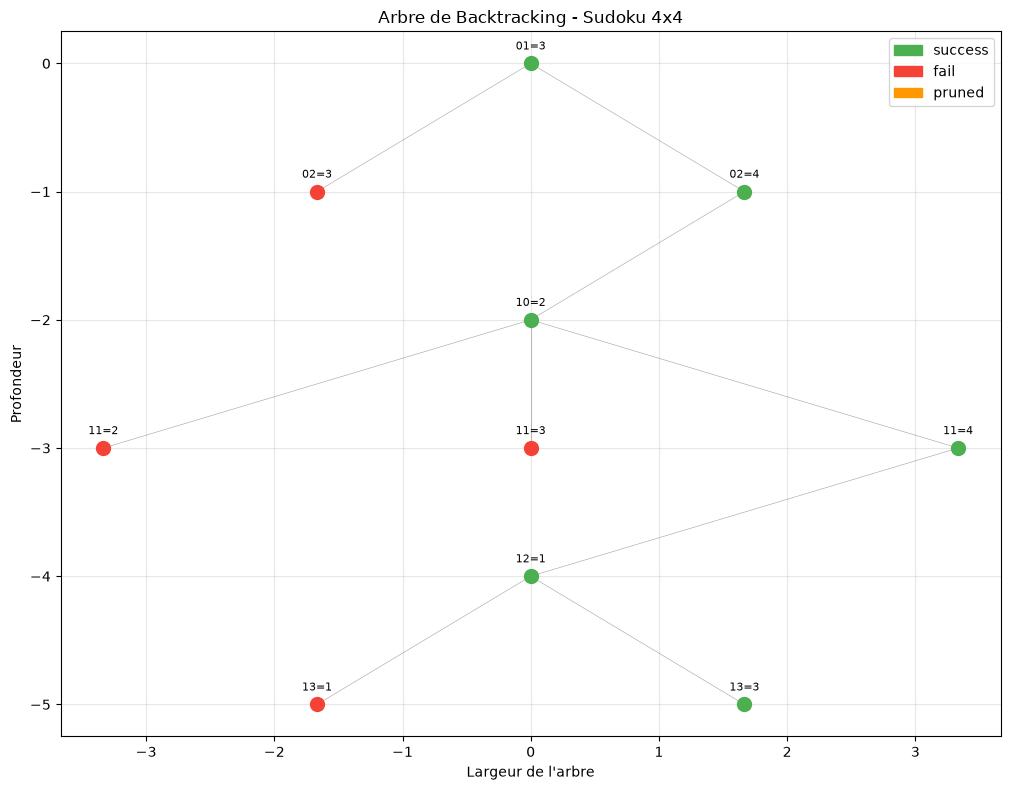

In [11]:
# Exemple guidé (crédité #22594) : Sudoku 4x4 avec visualisation

def make_sudoku_4x4_csp(initial_grid):
    """
    Cree un CSP pour un Sudoku 4x4.

    initial_grid : liste de 4 listes de 4 entiers (0 = vide)
    """
    cells = [(i, j) for i in range(4) for j in range(4)]

    def peers(i, j):
        """Cases de la meme ligne, colonne et bloc 2x2 que (i, j), sauf (i, j)."""
        p = set()
        for k in range(4):
            p.add((i, k))   # meme ligne
            p.add((k, j))   # meme colonne
        bi, bj = 2 * (i // 2), 2 * (j // 2)
        for a in range(bi, bi + 2):
            for b in range(bj, bj + 2):
                p.add((a, b))   # meme bloc 2x2
        p.discard((i, j))
        return p

    # Variables : (ligne, colonne) -> une variable "ij" par case vide
    variables = [f"{i}{j}" for (i, j) in cells if initial_grid[i][j] == 0]

    domains, neighbors = {}, {}
    for v in variables:
        i, j = int(v[0]), int(v[1])
        # Domaine : {1, 2, 3, 4} prive des indices deja presents chez les voisins
        fixed = {initial_grid[a][b] for (a, b) in peers(i, j) if initial_grid[a][b] != 0}
        domains[v] = [d for d in [1, 2, 3, 4] if d not in fixed]
        # Contraintes : lignes, colonnes, blocs 2x2 (voisins encore vides)
        neighbors[v] = [f"{a}{b}" for (a, b) in sorted(peers(i, j))
                        if initial_grid[a][b] == 0]

    # Deux voisins doivent avoir des valeurs differentes
    return CSP(variables, domains, neighbors, lambda v1, x, v2, y: x != y)


initial = [
    [1, 0, 0, 2],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [3, 0, 0, 4]
]

sudoku_csp = make_sudoku_4x4_csp(initial)
solution, viz = backtracking_with_viz(sudoku_csp)

n_fail = sum(1 for n in viz.nodes if n[3] == 'fail')
n_ok = len(viz.nodes) - n_fail

print(f"Variables : {len(sudoku_csp.variables)} cases vides")
print(f"Solution  : {solution}")
print(f"Valide    : {sudoku_csp.is_solution(solution)}")
print(f"Noeuds explores : {len(viz.nodes)}, dont {n_fail} rejets et {n_ok} assignations retenues")
print(f"Chemin final    : {len(viz.current_path)} noeuds -> {n_ok - len(viz.current_path)} retour(s) arriere")

grille = [row[:] for row in initial]
for v, val in solution.items():
    grille[int(v[0])][int(v[1])] = val
print("Grille resolue :")
for row in grille:
    print(row)

viz.draw(max_depth=5, title="Arbre de Backtracking - Sudoku 4x4")

### Lecture du résultat : 12 variables, 28 nœuds, 3 retours arrière

L'arbre est plus large que celui de la carte d'Australie (11 nœuds) alors que le problème paraît plus petit : 12 cases vides contre 7 régions. Deux raisons se lisent dans la sortie. D'abord les domaines : les quatre indices fixés ne ramènent chaque case qu'à deux ou trois valeurs, mais le parcours suit l'ordre d'insertion des variables (`"01"`, `"02"`, `"10"`, …) et non MRV. Ensuite l'ordre des valeurs : rien ne suggère d'essayer d'abord la valeur la plus contraignante, donc des branches entières sont ouvertes avant d'être abandonnées.

| Mesure | Valeur | Ce qu'elle signifie |
|---|---|---|
| Variables | 12 | cases vides de la grille de départ |
| Nœuds explorés | 28 | tentatives d'assignation, retenues ou rejetées |
| Rejets immédiats | 13 | conflits vus par `consistent()` avant toute récursion : branches coupées à la naissance |
| Assignations retenues | 15 | `28 - 13` |
| Retours arrière | 3 | `15 - 12` : assignations retenues qui ne sont pas dans le chemin final, donc défaites |

Le dernier nombre se calcule sans instrument dédié : chaque assignation retenue allonge le chemin courant d'un nœud, chaque retour arrière le raccourcit d'un. À la fin le chemin mesure la taille de la solution (12), et l'écart avec les assignations retenues (15) compte exactement les retours arrière. C'est la même identité que sur la carte d'Australie, où les 11 nœuds se décomposaient en 7 assignations retenues et 4 rejets.

Deux points à retenir pour la suite. Le premier est que **la solution trouvée n'est pas la solution** : cette grille de départ n'a que quatre indices, et plusieurs complétions la respectent. `backtracking_with_viz` s'arrête sur la première (le `return` dès que l'assignation est complète) ; compter toutes les solutions est un autre problème — l'énumération, pas la recherche. Le second est que **`is_solution` ne vaut que ce que le modèle déclare** : elle ne vérifie que les arêtes présentes dans `neighbors`, si bien qu'un modèle incomplet se valide lui-même. L'exercice 4 exploite précisément ce point.

***

## 5. Heuristiques : MRV et LCV (~8 min)

Le backtracking simple fonctionne, mais deux choix stratégiques peuvent considérablement l'accélérer :

1. **Quelle variable** assigner ensuite ? (variable ordering)
2. **Quelle valeur** essayer en premier ? (value ordering)

### 5.1 Variable Ordering : MRV (Minimum Remaining Values)

**Principe** : choisir la variable qui a le **plus petit domaine restant** (le moins de valeurs viables).

**Intuition ("fail-first")** : si une variable n'a que 2 valeurs possibles et une autre en a 10, mieux vaut traiter d'abord celle à 2 valeurs. Si elle échoue, on le découvre plus vite, et on élague un sous-arbre plus tot.

$$\text{MRV}(X_i) = |\{v \in D_i : v \text{ est consistant avec l'assignation courante}\}|$$

On choisit $X_i$ qui minimise $\text{MRV}(X_i)$.

In [12]:
def select_mrv(csp, assignment):
    """Heuristique MRV : choisir la variable avec le moins de valeurs viables.

    En cas d'egalite, departage par degree heuristic (nombre de voisins
    non assignes, en ordre decroissant).
    """
    unassigned = [v for v in csp.variables if v not in assignment]

    def remaining_values(var):
        return sum(1 for val in csp.domains[var]
                   if csp.consistent(var, val, assignment))

    def degree(var):
        return sum(1 for n in csp.neighbors[var] if n not in assignment)

    # MRV croissant, puis degree decroissant en cas d'egalite
    return min(unassigned, key=lambda v: (remaining_values(v), -degree(v)))

print("Heuristique MRV definie.")

Heuristique MRV definie.


Illustrons le choix MRV : après quelques assignations, voyons quelle variable est selectionnee et pourquoi.

In [13]:
# Demonstration du choix MRV
demo_csp = CSP(australia_vars, australia_domains,
               australia_neighbors, different_values)
partial = {'WA': 'Rouge', 'NT': 'Vert'}  # assignation partielle

print("Assignation partielle : WA=Rouge, NT=Vert")
print("\nValeurs restantes viables pour chaque variable non assignee :")
print(f"{'Variable':<8} {'Valeurs viables':<30} {'MRV':>5} {'Degree':>8}")
print("-" * 55)

for var in demo_csp.variables:
    if var not in partial:
        viable = [val for val in demo_csp.domains[var]
                  if demo_csp.consistent(var, val, partial)]
        deg = sum(1 for n in demo_csp.neighbors[var] if n not in partial)
        print(f"{var:<8} {str(viable):<30} {len(viable):>5} {deg:>8}")

chosen = select_mrv(demo_csp, partial)
print(f"\n=> MRV selectionne : {chosen} (domaine le plus restreint, puis degre le plus eleve)")

Assignation partielle : WA=Rouge, NT=Vert

Valeurs restantes viables pour chaque variable non assignee :
Variable Valeurs viables                  MRV   Degree
-------------------------------------------------------
SA       ['Bleu']                           1        3
Q        ['Rouge', 'Bleu']                  2        2
NSW      ['Rouge', 'Vert', 'Bleu']          3        3
V        ['Rouge', 'Vert', 'Bleu']          3        2
T        ['Rouge', 'Vert', 'Bleu']          3        0

=> MRV selectionne : SA (domaine le plus restreint, puis degre le plus eleve)


### Interprétation : sélection MRV

**Sortie obtenue** : après avoir assigné WA=Rouge et NT=Vert, SA n'a plus qu'une seule valeur viable (Bleu), car elle est adjacente aux deux régions déjà coloriées.

| Variable | Valeurs viables | Pourquoi |
|----------|----------------|----------|
| SA | [Bleu] seulement | Adjacent a WA (Rouge) et NT (Vert) |
| Q, NSW | 2 valeurs | Adjacents à certaines variables assignées |
| V, T | 3 valeurs | Pas ou peu de voisins assignes |

MRV choisit SA car c'est la variable la plus contrainte. Si SA n'a aucune valeur viable, on détecte l'échec immédiatement sans explorer les autres variables.

### 5.2 Value Ordering : LCV (Least Constraining Value)

**Principe** : pour la variable choisie, essayer d'abord la valeur qui **élimine le moins de possibilités** pour les variables voisines non assignées.

**Intuition ("succeed-first")** : contrairement au "fail-first" pour les variables, pour les valeurs on préfère maximiser les chances que le reste du problème reste soluble.

$$\text{LCV}(v) = \sum_{\text{voisin } Y \text{ non assigné}} |\{w \in D_Y : \text{contrainte}(X, v, Y, w) \text{ violée}\}|$$

On trie les valeurs par nombre de conflits croissant (la moins contraignante d'abord).

In [14]:
def order_lcv(csp, var, assignment):
    """Heuristique LCV : trier les valeurs par nombre de conflits croissant."""
    def conflicts(val):
        count = 0
        for neighbor in csp.neighbors[var]:
            if neighbor not in assignment:
                for nval in csp.domains[neighbor]:
                    if not csp.constraint_func(var, val, neighbor, nval):
                        count += 1
        return count

    return sorted(csp.domains[var], key=conflicts)

print("Heuristique LCV definie.")

Heuristique LCV definie.


### Backtracking amélioré : MRV + LCV

Combinons les deux heuristiques dans une version améliorée du backtracking.

In [15]:
def backtracking_improved(csp, assignment=None,
                          use_mrv=True, use_lcv=True):
    """Backtracking avec heuristiques MRV et LCV."""
    if assignment is None:
        assignment = {}

    if csp.is_complete(assignment):
        return assignment

    # Selection de variable
    if use_mrv:
        var = select_mrv(csp, assignment)
    else:
        unassigned = [v for v in csp.variables if v not in assignment]
        var = unassigned[0]

    # Ordre des valeurs
    if use_lcv:
        values = order_lcv(csp, var, assignment)
    else:
        values = csp.domains[var]

    for val in values:
        csp.n_assigns += 1
        if csp.consistent(var, val, assignment):
            assignment[var] = val
            result = backtracking_improved(csp, assignment, use_mrv, use_lcv)
            if result is not None:
                return result
            del assignment[var]

    return None

print("Backtracking ameliore defini.")

Backtracking ameliore defini.


### Benchmark : plain backtracking vs MRV vs MRV+LCV

Comparons les différentes variantes sur le problème de coloration australienne.

In [16]:
# Comparaison des variantes sur la coloration de l'Australie
variants = [
    ("Backtracking simple", False, False),
    ("+ MRV",              True,  False),
    ("+ MRV + LCV",        True,  True),
]

results_australia = []

print("Comparaison des variantes - Coloration Australie")
print("=" * 55)
print(f"{'Variante':<25} {'Assignations':>12} {'Temps (ms)':>12}")
print("-" * 55)

for name, mrv, lcv in variants:
    csp = CSP(australia_vars, australia_domains,
              australia_neighbors, different_values)
    start = time.time()
    sol = backtracking_improved(csp, use_mrv=mrv, use_lcv=lcv)
    elapsed = (time.time() - start) * 1000

    results_australia.append({
        'name': name,
        'assigns': csp.n_assigns,
        'time_ms': elapsed,
        'solution': sol
    })
    print(f"{name:<25} {csp.n_assigns:>12} {elapsed:>12.2f}")

print(f"\nToutes les variantes trouvent une solution valide.")

Comparaison des variantes - Coloration Australie
Variante                  Assignations   Temps (ms)
-------------------------------------------------------
Backtracking simple                 11         0.02
+ MRV                               15         0.08
+ MRV + LCV                         15         0.09

Toutes les variantes trouvent une solution valide.


### Interprétation : impact des heuristiques sur la coloration

**Sortie obtenue** : sur ce petit graphe, les heuristiques n'améliorent pas le compte d'assignations.

| Variante | Assignations | Commentaire |
|----------|-------------|-------------|
| Backtracking simple | 11 | Ordre naïf des variables et valeurs |
| + MRV | 15 | Fail-first : sur-coût ici non amorti |
| + MRV + LCV | 15 | idem, LCV ne change rien |

**Points clés** :
1. Sur ce petit problème (7 variables, 3 couleurs, espace déjà très contraint), l'ordre naïf tombe déjà sur une solution en 11 assignations ; MRV ajoute ici un sur-coût de sélection (15) non amorti
2. L'effet des heuristiques est **instance-dependant** : nul ou negatif sur une instance facile, il devient dramatique sur des instances plus dures (cf. les 8-Reines ci-dessous : 876 -> 572 avec MRV)
3. Conclusion honnête : aucune heuristique n'est monotoniquement bénéfique, il faut mesurer et non présupposer une amélioration

> **règle pratique** : mesurer empiriquement. MRV rapporte gros sur les instances dures (N-Reines), mais son sur-coût n'est pas amorti sur les instances faciles comme la coloration de l'Australie.

Visualisons l'impact des heuristiques sur les deux problèmes : coloration et N-Reines.

In [17]:
# N-Reines : definition du probleme
def make_nqueens_csp(n):
    """Cree un CSP pour le probleme des N-Reines."""
    variables = list(range(n))  # colonnes 0..n-1
    domains = {col: list(range(n)) for col in variables}
    neighbors = {col: [c for c in variables if c != col] for col in variables}

    def queens_constraint(c1, r1, c2, r2):
        if r1 == r2:
            return False  # meme ligne
        if abs(c1 - c2) == abs(r1 - r2):
            return False  # meme diagonale
        return True

    return CSP(variables, domains, neighbors, queens_constraint)


def draw_queens(solution, n, title="Solution N-Reines"):
    """Visualise la solution du probleme des N-Reines."""
    fig, ax = plt.subplots(figsize=(max(6, n * 0.8), max(6, n * 0.8)))

    for row in range(n):
        for col in range(n):
            color = '#F0D9B5' if (row + col) % 2 == 0 else '#B58863'
            rect = plt.Rectangle((col, n - 1 - row), 1, 1,
                                 facecolor=color, edgecolor='black')
            ax.add_patch(rect)

    if solution:
        for col, row in solution.items():
            ax.text(col + 0.5, n - 1 - row + 0.5, 'Q',
                    ha='center', va='center', fontsize=max(8, 24 - n),
                    fontweight='bold', color='darkred')

    ax.set_xlim(0, n)
    ax.set_ylim(0, n)
    ax.set_aspect('equal')
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(range(n))
    ax.set_yticklabels(range(n - 1, -1, -1))
    ax.set_xlabel('Colonne')
    ax.set_ylabel('Ligne')
    ax.set_title(title, fontsize=13, fontweight='bold')
    plt.tight_layout()
    return fig

print("Fonctions N-Reines definies.")

Fonctions N-Reines definies.


Resolvons le problème des 8-Reines et visualisons le résultat, puis comparons les variantes.

Probleme des 8-Reines
Solution (col -> ligne) : {0: 0, 1: 4, 2: 7, 3: 5, 6: 1, 4: 2, 5: 6, 7: 3}
Assignations tentees   : 677
Temps                  : 3.16 ms
Verification           : VALIDE


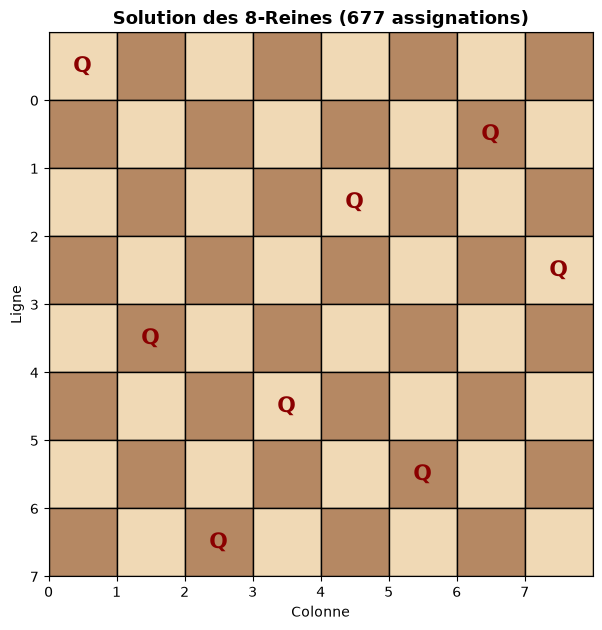

In [18]:
# Resolution et visualisation des 8-Reines
n = 8
csp_queens = make_nqueens_csp(n)

start = time.time()
sol_queens = backtracking_improved(csp_queens, use_mrv=True, use_lcv=True)
elapsed = (time.time() - start) * 1000

print(f"Probleme des {n}-Reines")
print("=" * 35)
print(f"Solution (col -> ligne) : {sol_queens}")
print(f"Assignations tentees   : {csp_queens.n_assigns}")
print(f"Temps                  : {elapsed:.2f} ms")
print(f"Verification           : {'VALIDE' if csp_queens.is_solution(sol_queens) else 'INVALIDE'}")

draw_queens(sol_queens, n, f"Solution des {n}-Reines ({csp_queens.n_assigns} assignations)")
plt.show()

### Lecture de l'ordre des clés : MRV rendu visible par le dictionnaire

Le détail révélateur de cette sortie est l'ordre des clés imprimé : `{0: 0, 1: 4, 2: 7, 3: 5, 6: 1, 4: 2, 5: 6, 7: 3}`. La colonne 6 apparaît en cinquième position, avant les colonnes 4 et 5. Un ordre d'assignation naïf aurait produit 0, 1, 2, 3, 4, 5, 6, 7 : l'écart témoigne que la sélection des variables a été réordonnée en cours de recherche — c'est MRV, qui a traité la colonne 6 plus tôt parce que son domaine viable était plus restreint à cet instant. L'ordre d'insertion d'un dict Python mémorise l'ordre des assignations : il rend l'heuristique observable sans instrumenter le code.

Deux vérifications arithmétiques sur les valeurs : les huit lignes {0, 4, 7, 5, 1, 2, 6, 3} sont exactement les entiers de 0 à 7, tous distincts — une reine par ligne, par construction du modèle (une variable par colonne) — et la ligne de vérification conclut `VALIDE`, diagonales incluses.

La comparaison des variantes se lit sur le même compte d'assignations :

| Mesure | Valeur |
|--------|--------|
| Espace brut | $8^8 = 16\,777\,216$ |
| Plain backtracking | 876 assignations |
| + MRV | 572 assignations |
| + MRV + LCV | 677 assignations |

MRV (876 -> 572) réduit nettement le compte ; en revanche, ajouter LCV le remonte à 677 : l'ordonnancement des valeurs par LCV est ici moins favorable que l'ordre naïf combiné à MRV -- c'est un effet connu, l'ordonnancement des valeurs étant moins robuste que celui des variables. Mise en perspective : 677 assignations face à l'espace brut, soit environ 4 dix-millièmes de l'espace visité (un facteur de réduction d'environ 24 800). Le temps est une mesure machine-dépendante sur un seul passage, non moyennée : c'est le compte d'assignations, structurel, qui fait foi.

In [19]:
# Comparaison des variantes sur les deux problemes
def benchmark_csp(make_csp_func, csp_name, csp_args=None):
    """Benchmark des variantes de backtracking sur un CSP."""
    configs = [
        ("Plain backtracking", False, False),
        ("+ MRV",             True,  False),
        ("+ MRV + LCV",       True,  True),
    ]
    results = []
    for name, mrv, lcv in configs:
        csp = make_csp_func() if csp_args is None else make_csp_func(*csp_args)
        start = time.time()
        sol = backtracking_improved(csp, use_mrv=mrv, use_lcv=lcv)
        elapsed = (time.time() - start) * 1000
        results.append({
            'name': name,
            'assigns': csp.n_assigns,
            'time_ms': elapsed,
            'found': sol is not None
        })
    return results

def make_australia():
    return CSP(australia_vars, australia_domains,
              australia_neighbors, different_values)

res_map = benchmark_csp(make_australia, "Coloration Australie")
res_queens = benchmark_csp(make_nqueens_csp, "8-Reines", csp_args=(8,))

# Tableau comparatif
print("Tableau comparatif des variantes")
print("=" * 70)
print(f"{'Variante':<22} {'Map (assigns)':>14} {'8-Reines (assigns)':>20}")
print("-" * 70)
for rm, rq in zip(res_map, res_queens):
    print(f"{rm['name']:<22} {rm['assigns']:>14} {rq['assigns']:>20}")
print("=" * 70)

Tableau comparatif des variantes
Variante                Map (assigns)   8-Reines (assigns)
----------------------------------------------------------------------
Plain backtracking                 11                  876
+ MRV                              15                  572
+ MRV + LCV                        15                  677


Representons graphiquement les résultats du benchmark pour mieux visualiser l'ecart entre les variantes.

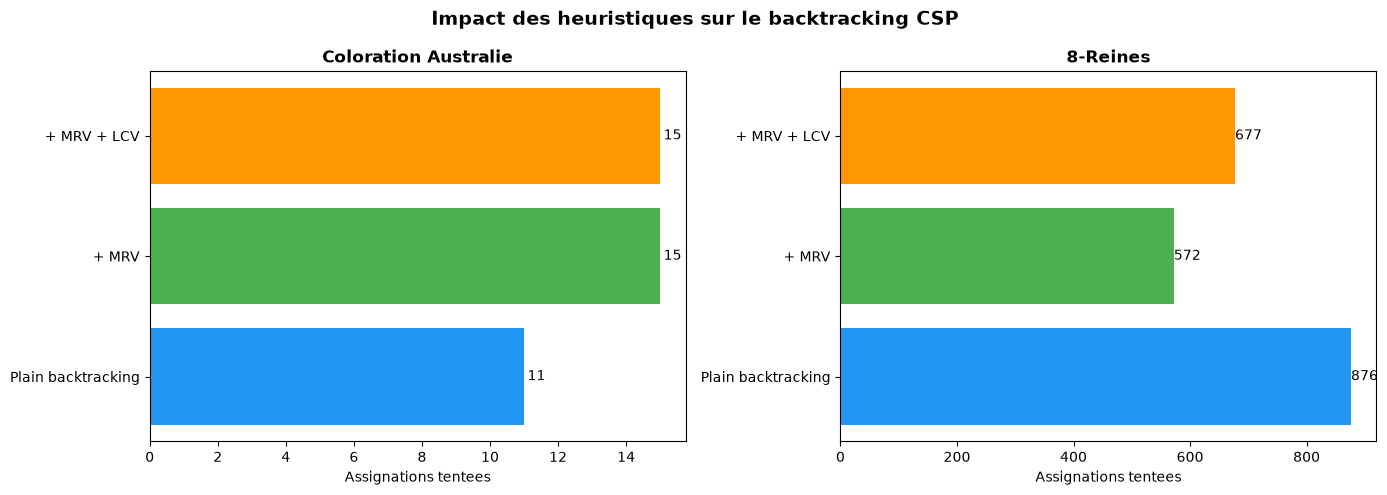

In [20]:
# Visualisation comparative
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

names = [r['name'] for r in res_map]
assigns_map = [r['assigns'] for r in res_map]
axes[0].barh(names, assigns_map, color=['#2196F3', '#4CAF50', '#FF9800'])
axes[0].set_xlabel('Assignations tentees')
axes[0].set_title('Coloration Australie', fontweight='bold')
for i, v in enumerate(assigns_map):
    axes[0].text(v + 0.1, i, str(v), va='center', fontsize=10)

assigns_q = [r['assigns'] for r in res_queens]
axes[1].barh(names, assigns_q, color=['#2196F3', '#4CAF50', '#FF9800'])
axes[1].set_xlabel('Assignations tentees')
axes[1].set_title('8-Reines', fontweight='bold')
for i, v in enumerate(assigns_q):
    axes[1].text(v + 0.1, i, str(v), va='center', fontsize=10)

plt.suptitle('Impact des heuristiques sur le backtracking CSP',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Interprétation : comparaison des variantes

| Variante | Coloration (assigns) | 8-Reines (assigns) | Ce qui change |
|----------|---------------------|---------------------|---------------|
| Plain backtracking | 11 | 876 | Ordre naïf des variables et des valeurs |
| + MRV | 15 | 572 | Fail-first : on assigne d'abord la variable la plus contrainte |
| + MRV + LCV | 15 | 677 | Succeed-first : on essaie d'abord la valeur la moins contraignante |

**Ce que ce tableau permet de dire, et ce qu'il ne permet pas.**

Sur les 8-Reines, MRV ramène la recherche de 876 à 572 assignations : l'espace de recherche y est grand, et le fail-first élimine des branches entières. Sur la carte d'Australie, les trois variantes terminent en 11 à 15 assignations : l'instance est trop petite pour que le choix de la variable ou de la valeur change quoi que ce soit. L'écart de quelques assignations y mesure le bruit d'exécution, pas une propriété des méthodes.

C'est aussi pourquoi LCV n'y change rien (15 -> 15) : le coût de conflit est identique pour toutes les couleurs candidates, donc le tri n'a aucun effet. Et sur les 8-Reines, il dégrade légèrement le résultat (572 -> 677) : un ordre des valeurs est une heuristique, pas une garantie — tester la valeur la moins contraignante peut mener à une impasse plus loin. Sur un problème symétrique comme les N-Reines, le tri des valeurs n'apporte pas d'information discriminante.

Un benchmark sur des instances choisies pour leur lisibilité ne permet donc pas de conclure que MRV « n'aide pas ». Il permet de conclure que l'instance choisie n'a rien à discriminer. La section suivante rejoue la même comparaison sur une famille dont la difficulté est paramétrable, pour mesurer à partir de quand les heuristiques deviennent décisives.

### 5.3 Un cadran de difficulté : quand la baseline triviale cesse de gagner

La section précédente a établi que la carte d'Australie n'a rien à discriminer : un terrain qui ne départage pas ne peut pas enseigner l'heuristique qu'il prétend démontrer. Pour savoir à partir de quand MRV et LCV deviennent décisives, il faut un terrain dont la difficulté est paramétrable. Nous construisons une famille de **coloration à listes de couleurs** (*list coloring*) : chaque région ne peut utiliser qu'un sous-ensemble des couleurs, tiré au sort. Deux réglages suffisent à faire basculer le terrain :

- **listes complètes** (`|L| = k`) : aucune restriction ; seule la structure du graphe compte ;
- **listes restreintes** (`|L| = 2`) : chaque région n'a que deux couleurs candidates au lieu de trois — et c'est cette restriction qui rend enfin discriminantes les deux heuristiques, MRV (chooisir la variable la plus contrainte) et LCV (préférer la valeur qui bloque le moins de voisins).

Les instances sont **plantées** : on tire une coloration cachée, on en déduit des listes de couleurs qui la contiennent, et on n'ajoute des arêtes qu'entre régions de couleurs différentes. La coloration cachée est donc toujours une solution valide : chaque instance est satisfaisable par construction, et le seul paramètre libre est la difficulté.

Le cadran complet est `(n, p, |L|)` : `n` régions, `p` probabilité d'arête entre deux régions de couleurs différentes, `|L|` taille des listes de couleurs. Nous fixons `n`, `k` et `p`, et nous faisons varier `|L|` : c'est le seul paramètre que l'on déplace entre les deux régimes. Les valeurs retenues sont affichées par le code ci-dessous.

**Les deux régimes partagent le même graphe.** Le générateur tire la coloration cachée, les arêtes et les listes depuis trois flux aléatoires distincts, dérivés de la même graine : pour une graine donnée, le graphe — coloration cachée et arêtes — est rigoureusement le même dans les deux régimes. Seul le contenu des listes change, puisque c'est là que se loge le paramètre `|L|` : la comparaison porte donc bien sur un graphe inchangé, et non sur deux instances sans lien.

In [21]:
# Cadran de difficulte : coloration a listes de couleurs, instances plantees
import random

GRAINES = [0, 1, 7, 42, 99]


def planted_list_coloring_csp(n, k, list_size, density, seed):
    """CSP de coloration a listes de couleurs, instance plantee (satisfaisable).

    Une coloration cachee est tiree au sort, puis chaque liste de couleurs
    contient la couleur cachee de sa region. Les aretes ne relient que des
    regions de couleurs differentes : la coloration cachee reste donc une
    solution valide, et seule la difficulte (taille des listes, densite)
    varie d'un regime a l'autre.

    Les trois tirages (coloration cachee, aretes, listes) utilisent des
    flux aleatoires distincts derives de la meme graine : pour une graine
    donnee, le graphe est donc rigoureusement le meme d'un regime a l'autre
    -- seul |L| bouge. Sans cette separation, le tirage des listes
    consommerait le flux avant celui des aretes, et les deux regimes
    compareraient deux graphes differents.
    """
    master = random.Random(seed)
    rng_planted = random.Random(master.getrandbits(64))
    rng_edges = random.Random(master.getrandbits(64))
    rng_listes = random.Random(master.getrandbits(64))

    planted = [rng_planted.randrange(k) for _ in range(n)]

    neighbors = {var: [] for var in range(n)}
    for i in range(n):
        for j in range(i + 1, n):
            if planted[i] != planted[j] and rng_edges.random() < density:
                neighbors[i].append(j)
                neighbors[j].append(i)

    domains = {}
    for var in range(n):
        couleurs = {planted[var]}
        while len(couleurs) < list_size:
            couleurs.add(rng_listes.randrange(k))
        domains[var] = sorted(couleurs)

    return CSP(list(range(n)), domains, neighbors, different_values)


def benchmark_list_coloring(n, k, list_size, density):
    """Assignations tentees par variante : moyenne et etendue sur plusieurs graines."""
    configs = [
        ("Plain backtracking", False, False),
        ("+ MRV",             True,  False),
        ("+ MRV + LCV",       True,  True),
    ]
    resultats = []
    for nom, mrv, lcv in configs:
        valeurs = []
        resolues = True
        for graine in GRAINES:
            csp = planted_list_coloring_csp(n, k, list_size, density, graine)
            solution = backtracking_improved(csp, use_mrv=mrv, use_lcv=lcv)
            valeurs.append(csp.n_assigns)
            resolues = resolues and solution is not None
        resultats.append({
            'nom': nom,
            'moyenne': sum(valeurs) / len(valeurs),
            'min': min(valeurs),
            'max': max(valeurs),
            'resolues': resolues,
        })
    return resultats


def afficher_regime(n, k, list_size, density, titre):
    """Affiche le tableau de mesures d'un regime de difficulte."""
    resultats = benchmark_list_coloring(n, k, list_size, density)
    print(titre)
    print(f"n={n}, k={k}, listes de {list_size} couleurs, p={density}, graines={GRAINES}")
    print("-" * 74)
    print(f"{'Variante':<22}{'moyenne':>12}{'min':>8}{'max':>8}{'resolues':>12}")
    print("-" * 74)
    for r in resultats:
        print(f"{r['nom']:<22}{r['moyenne']:>12.1f}{r['min']:>8}{r['max']:>8}{str(r['resolues']):>12}")
    print("=" * 74)
    return resultats


print("Regime 1 : listes completes (3 couleurs candidates par region)")
res_completes = afficher_regime(60, 3, 3, 0.8,
                                "Listes completes -- aucune restriction de domaine")

print()
print("Regime 2 : listes restreintes (2 couleurs candidates par region)")
res_restreintes = afficher_regime(60, 3, 2, 0.8,
                                  "Listes restreintes -- domaine reduit a deux couleurs")

print()
print("Ce que les heuristiques font gagner dans chaque regime")
print("-" * 74)
for titre, res in (("listes completes", res_completes),
                   ("listes restreintes", res_restreintes)):
    naif = res[0]['moyenne']
    mrv = res[1]['moyenne']
    both = res[2]['moyenne']
    print(f"{titre:<20} naif {naif:7.1f} | MRV {mrv:7.1f} | MRV+LCV {both:7.1f} "
          f"| rapport naif / (MRV+LCV) = {naif / both:.2f}")

Regime 1 : listes completes (3 couleurs candidates par region)
Listes completes -- aucune restriction de domaine
n=60, k=3, listes de 3 couleurs, p=0.8, graines=[0, 1, 7, 42, 99]
--------------------------------------------------------------------------
Variante                   moyenne     min     max    resolues
--------------------------------------------------------------------------
Plain backtracking           142.0     118     203        True
+ MRV                        129.8     126     137        True
+ MRV + LCV                  129.8     126     137        True

Regime 2 : listes restreintes (2 couleurs candidates par region)
Listes restreintes -- domaine reduit a deux couleurs
n=60, k=3, listes de 2 couleurs, p=0.8, graines=[0, 1, 7, 42, 99]
--------------------------------------------------------------------------
Variante                   moyenne     min     max    resolues
--------------------------------------------------------------------------
Plain backtracking   

### Lecture : le terrain décide de la marge, pas du gagnant

| Régime | Backtracking naïf | + MRV | + MRV + LCV |
|---|---|---|---|
| Listes complètes (3 couleurs candidates) | 142.0 | 129.8 | 129.8 |
| Listes restreintes (2 couleurs candidates) | 100.8 | 91.2 | 69.0 |

Moyenne des assignations tentées sur cinq graines fixées (0, 1, 7, 42, 99) ; les deux régimes sont résolus sur toutes les graines. Les deux régimes partagent le **même graphe** pour une graine donnée — la coloration cachée et les arêtes sont tirées depuis des flux distincts de celui des listes — : seul le contenu des listes change entre les deux.

Quatre lectures :

1. **En régime listes complètes, les méthodes sont presque indifférenciables.** Le naïf explore 142.0 assignations en moyenne, MRV 129.8 : l'écart existe mais reste faible (rapport 1.09). LCV ne change rien du tout (129.8 exactement comme MRV) : quand le domaine d'une variable contient toutes les couleurs, trier les valeurs par nombre de conflits ne peut pas les départager, tous les conflits se valent.

2. **En régime listes restreintes, la marge se creuse.** Le naïf passe à 100.8 assignations, MRV à 91.2, et MRV + LCV à 69.0 : le gain de LCV sur MRV se lit dans l'écart 91.2 → 69.0. Le rapport naïf / (MRV + LCV) passe de 1.09 à 1.46 : ce qui grandit est l'écart, pas l'ordre des méthodes — le naïf reste le moins bon dans les deux régimes. Les intervalles le confirment (le maximum de MRV + LCV, 74, reste sous le minimum du naïf, 90) : l'écart ne repose pas sur la seule moyenne.

3. **Restreindre les listes fait travailler le naïf moins, et creuse l'écart avec les heuristiques.** Le compte du naïf *baisse* (142.0 → 100.8) : un domaine réduit rétrécit l'arbre de recherche même sans guidage. La valeur des heuristiques se lit donc dans le **rapport**, pas dans le compte brut — et c'est ce rapport qui grandit quand le terrain se contraint.

4. **Le contre-résultat de la section précédente n'était pas un fait sur les heuristiques.** Sur la carte d'Australie, le naïf l'emportait (11 contre 15) — mais l'instance était trop petite pour discriminer. Ici, sur un terrain dont la difficulté est paramétrée, le naïf ne l'emporte dans aucun des deux régimes. Ce que le benchmark de la carte d'Australie mesurait, c'était la platitude du terrain — pas la valeur de la méthode.

> **À retenir** : avant de comparer deux méthodes, vérifier que le terrain les départage. Un benchmark qui conclut « l'heuristique n'aide pas » sur une instance triviale ne mesure rien ; il faut déplacer le paramètre de difficulté jusqu'à ce que l'écart apparaisse, et rapporter les deux regimes côte à côte.

***

## 6. Bibliothèque python-constraint (~8 min)

Jusqu'ici nous avons tout implémenté de zéro, ce qui est essentiel pour comprendre les mécanismes. En pratique, on utilise souvent une **bibliothèque CSP** qui fournit un solveur optimisé et des contraintes prédéfinies.

La bibliothèque [`python-constraint`](https://github.com/python-constraint/python-constraint) permet de modéliser et résoudre des CSP de manière déclarative.

### Installation

```bash
pip install python-constraint
```

In [22]:
# Installation si necessaire
import sys
try:
    from constraint import Problem, AllDifferentConstraint
    print("python-constraint importe avec succes.")
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'python-constraint'])
    from constraint import Problem, AllDifferentConstraint
    print("python-constraint installe et importe.")

python-constraint importe avec succes.


### Coloration de l'Australie avec python-constraint

Réécrivons le problème de coloration de l'Australie avec la bibliothèque. Comparons la concision du code avec notre implémentation manuelle.

In [23]:
from constraint import Problem, AllDifferentConstraint
import time

# Coloration Australie avec python-constraint
problem = Problem()

# Variables et domaines
colors = ['Rouge', 'Vert', 'Bleu']
problem.addVariables(['WA', 'NT', 'SA', 'Q', 'NSW', 'V', 'T'], colors)

# Contraintes : regions adjacentes differentes
adjacencies = [
    ('WA', 'NT'), ('WA', 'SA'), ('NT', 'SA'), ('NT', 'Q'),
    ('SA', 'Q'), ('SA', 'NSW'), ('SA', 'V'),
    ('Q', 'NSW'), ('NSW', 'V')
]
for v1, v2 in adjacencies:
    problem.addConstraint(lambda a, b: a != b, (v1, v2))

# Trouver une solution
start = time.time()
sol_lib = problem.getSolution()
elapsed = (time.time() - start) * 1000

print("python-constraint - Coloration Australie")
print("=" * 45)
print(f"Solution : {sol_lib}")
print(f"Temps    : {elapsed:.2f} ms")

# Trouver TOUTES les solutions
start = time.time()
all_solutions = problem.getSolutions()
elapsed_all = (time.time() - start) * 1000

print(f"\nNombre total de solutions : {len(all_solutions)}")
print(f"Temps (toutes solutions)  : {elapsed_all:.2f} ms")

python-constraint - Coloration Australie
Solution : {'SA': 'Bleu', 'NSW': 'Vert', 'Q': 'Rouge', 'NT': 'Vert', 'V': 'Rouge', 'WA': 'Rouge', 'T': 'Bleu'}
Temps    : 0.15 ms

Nombre total de solutions : 18
Temps (toutes solutions)  : 0.34 ms


### Lecture croisée : premières solutions différentes, compte identique

La solution renvoyée ici commence par `{'SA': 'Bleu', 'NSW': 'Vert', 'Q': 'Rouge', ...}` — un ordre de clés et une coloration qui diffèrent du backtracking manuel (WA en premier, T = Rouge) : la bibliothèque attribue ici T = Bleu. Aucune incohérence : chaque solveur visite l'espace dans son propre ordre, et la première solution rencontrée dépend de cet ordre. Sur un problème à solutions multiples, comparer des premiers résultats n'a de sens qu'à parcours fixe ; seuls les comptes exhaustifs sont comparables.

La grandeur qui doit coïncider coïncide : `Nombre total de solutions : 18`, exactement les 18 solutions comptées par la brute force en section 4. Deux moteurs indépendants, un même espace de solutions — la vérification croisée la plus forte disponible sur ce problème.

Le reste de la comparaison est d'ordre d'API, pas de résultat :

| Aspect | Implémentation manuelle | python-constraint |
|--------|------------------------|-------------------|
| Lignes de code | ~60 (classe CSP + backtracking) | ~10 |
| Toutes les solutions | Nécessiterait une modification | `getSolutions()` intégré |
| Contraintes prédéfinies | À coder soi-même | `AllDifferentConstraint`, etc. |
| Pedagogie | Comprendre les mécanismes | Utiliser en production |

Côté coûts, honnêtement : les temps imprimés (pour la première solution, pour les 18) sont machine-dépendants et non moyennés. Surtout, le solveur interne de la bibliothèque n'est pas instrumenté ici : contrairement à notre classe CSP, aucun compteur d'assignations n'est exposé. On ne sait donc pas combien d'essais internes coûtent ce temps — la comparaison avec le backtracking manuel (11 assignations chiffrées) reste asymétrique.

### AllDifferentConstraint

La contrainte globale `AllDifferentConstraint` impose que toutes les variables d'un groupe prennent des valeurs distinctes. C'est la contrainte la plus frequente en pratique (Sudoku, emplois du temps, N-Reines).

In [24]:
# Demonstration AllDifferentConstraint
# 4 variables devant toutes etre differentes, domaine {1, 2, 3, 4}
p = Problem()
p.addVariables(['A', 'B', 'C', 'D'], [1, 2, 3, 4])
p.addConstraint(AllDifferentConstraint())

solutions = p.getSolutions()
print(f"AllDifferent sur 4 variables, domaine {{1,2,3,4}}")
print(f"Nombre de solutions : {len(solutions)}  (= 4! = {4*3*2*1})")
print(f"\nExemples (3 premieres) :")
for s in solutions[:3]:
    print(f"  {s}")

AllDifferent sur 4 variables, domaine {1,2,3,4}
Nombre de solutions : 24  (= 4! = 24)

Exemples (3 premieres) :
  {'A': 4, 'B': 3, 'C': 2, 'D': 1}
  {'A': 4, 'B': 3, 'C': 1, 'D': 2}
  {'A': 4, 'B': 2, 'C': 3, 'D': 1}


### Lecture : une contrainte globale fait passer l'espace de 256 à 24

La sortie affiche `Nombre de solutions : 24  (= 4! = 24)` et la vérification est immédiate : quatre variables sur un domaine de quatre valeurs, toutes différentes — chaque solution est une permutation de {1, 2, 3, 4}, et il y en a exactement 4 x 3 x 2 x 1 = 24.

La réduction se quantifie par rapport à l'espace non contraint : sans AllDifferent, l'espace brut serait 4^4 = 256. Une seule contrainte globale suffit à le diviser par 256 / 24, soit environ 10,7 — et ce, avant toute recherche : c'est de la propagation déclarative, pas de l'élagage pendant le parcours. C'est tout l'intérêt des contraintes globales face à la décomposition en contraintes binaires équivalentes : le solveur raisonne sur la structure entière du groupe.

Les trois solutions échantillonnées en fin de sortie se vérifient au vol : `{'A': 4, 'B': 3, 'C': 2, 'D': 1}`, `{'A': 4, 'B': 3, 'C': 1, 'D': 2}`, `{'A': 4, 'B': 2, 'C': 3, 'D': 1}` — chacune contient les quatre valeurs exactement une fois. Leur ordre (A = 4 en tête partout, puis B décroissant) révèle l'énumération lexicographique descendante du solveur : utile pour prévoir quelle solution un `getSolution()` renverra en premier.

Cette brique est celle qui porte la dureté des modèles réels — le Sudoku en est l'illustration canonique.


### 4-Reines avec python-constraint

Modélisons le problème des 4-Reines avec la bibliothèque pour montrer sa simplicité.

Probleme des 4-Reines (python-constraint)
Nombre de solutions : 2
Temps               : 0.17 ms

Solutions :
  Solution 1 : lignes = [2, 0, 3, 1]
  Solution 2 : lignes = [1, 3, 0, 2]


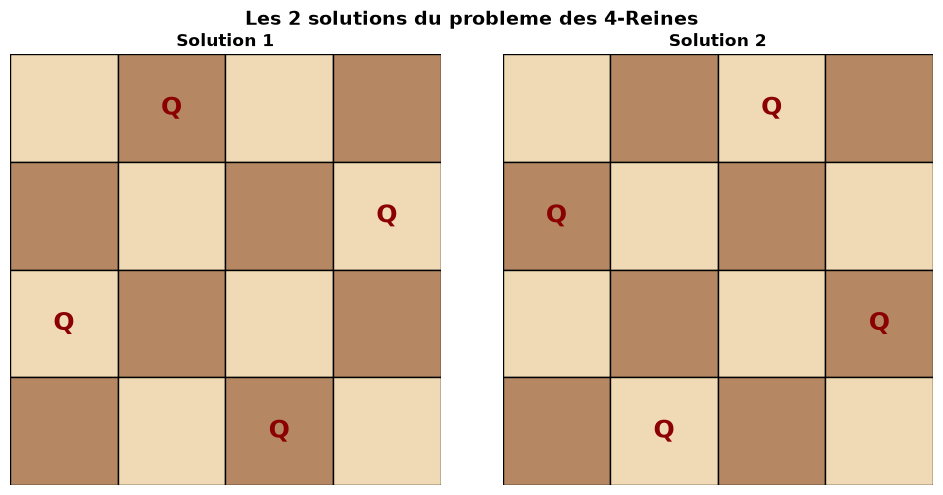

In [25]:
import matplotlib.pyplot as plt
# 4-Reines avec python-constraint
n = 4
queens_problem = Problem()

# Variables : Q0, Q1, Q2, Q3 (colonne -> ligne)
queens_problem.addVariables(range(n), range(n))

# Contraintes : pas meme ligne, pas meme diagonale
for i in range(n):
    for j in range(i + 1, n):
        # Pas meme ligne et pas meme diagonale
        queens_problem.addConstraint(
            lambda qi, qj, d=j-i: qi != qj and abs(qi - qj) != d,
            (i, j)
        )

# Toutes les solutions
start = time.time()
queens_solutions = queens_problem.getSolutions()
elapsed = (time.time() - start) * 1000

print(f"Probleme des {n}-Reines (python-constraint)")
print("=" * 45)
print(f"Nombre de solutions : {len(queens_solutions)}")
print(f"Temps               : {elapsed:.2f} ms")
print(f"\nSolutions :")
for i, sol in enumerate(queens_solutions):
    placement = [sol[col] for col in range(n)]
    print(f"  Solution {i+1} : lignes = {placement}")

# Visualiser les 2 solutions
fig, axes = plt.subplots(1, len(queens_solutions), figsize=(5 * len(queens_solutions), 5))
if len(queens_solutions) == 1:
    axes = [axes]
for idx, sol in enumerate(queens_solutions):
    ax = axes[idx]
    for row in range(n):
        for col in range(n):
            color = '#F0D9B5' if (row + col) % 2 == 0 else '#B58863'
            rect = plt.Rectangle((col, n - 1 - row), 1, 1,
                                 facecolor=color, edgecolor='black')
            ax.add_patch(rect)
    for col in range(n):
        row = sol[col]
        ax.text(col + 0.5, n - 1 - row + 0.5, 'Q',
                ha='center', va='center', fontsize=18,
                fontweight='bold', color='darkred')
    ax.set_xlim(0, n)
    ax.set_ylim(0, n)
    ax.set_aspect('equal')
    ax.set_title(f"Solution {idx+1}", fontweight='bold')
    ax.axis('off')

plt.suptitle(f"Les {len(queens_solutions)} solutions du probleme des {n}-Reines",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Lecture : les deux solutions sont miroirs, vérifiable en une ligne

La sortie liste exactement deux placements : `Solution 1 : lignes = [2, 0, 3, 1]` et `Solution 2 : lignes = [1, 3, 0, 2]`. La relation entre les deux se vérifie terme à terme : 3 - 2 = 1, 3 - 0 = 3, 3 - 3 = 0, 3 - 1 = 2. La seconde solution est l'image miroir verticale de la première — chaque reine garde sa colonne et passe à la ligne symétrique par rapport à l'axe horizontal de l'échiquier. Propriété remarquable de cette paire : la lecture inversée de la première liste, [1, 3, 0, 2], redonne aussi la seconde — sur cette instance, la réflexion des colonnes produit le même résultat que la réflexion des lignes.

Pourquoi seulement deux ? L'espace brut est 4^4 = 256 placements ; les contraintes de ligne et de diagonale, imposées paire à paire dans le modèle, ne laissent que ces deux placements valides. Les damiers imprimés le confirment visuellement : aucune paire de reines ne partage une ligne, une colonne ou une diagonale.

Généralisation sûre : le miroir d'une solution est toujours une solution (les contraintes sont invariantes par réflexion), donc les solutions vont par paires miroirs — un comptage impair serait suspect a posteriori. Le temps est machine-dépendant, un seul passage ; la grandeur structurelle est le compte : 2.

> **Quand utiliser quoi ?** Implémentation manuelle pour **apprendre** les mécanismes. Bibliothèque pour **résoudre** des problèmes réels.

***
## 6bis. Tranche lib-vs-lib : le même solveur que le jumeau .NET -- Choco via pychoco (~6 min)

La section 6 a utilise `python-constraint`, un moteur CSP pur Python. Le **jumeau .NET** de ce notebook ([CSP-1-Fundamentals-CSharp](CSP-1-Fundamentals-CSharp.ipynb)) resout ces mêmes problemes avec **Choco-solver 4.10.17** (solveur Java industriel, Apache-2.0) via le pont IKVM.

`pychoco` (PyPI, MIT) est le binding Python officiel du **même solveur Choco** : avec lui, les deux jumeaux atteignent le **même moteur de production** -- l'un via pont .NET/IKVM, l'autre via binding natif Python. C'est la parite *lib-vs-lib* stricte (gabarit Tweety-5 : socle from-scratch en tranche 1, lib reelle en tranche 2).

Nous rejouons ici les trois demonstrations Choco du jumeau C# : coloration de l'Australie, enumeration exhaustive, puis 8-Reines.


In [26]:
# Installation si necessaire
import sys
try:
    import pychoco
    print("pychoco importe avec succes.")
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'pychoco'])
    import pychoco
    print("pychoco installe et importe.")


pychoco importe avec succes.


### Coloration de l'Australie avec Choco

Même modèle que le jumeau C# : une `IntVar` par etat, domaine {0, 1, 2}, contrainte `!=` entre regions adjacentes.


In [27]:
import time
import pychoco

# Coloration de l'Australie avec Choco (pychoco)
choc_model = pychoco.Model()
choc_vars = {v: choc_model.intvar(0, 2) for v in australia_vars}
for v1 in australia_vars:
    for v2 in australia_neighbors[v1]:
        choc_model.arithm(choc_vars[v1], "!=", choc_vars[v2]).post()

choc_solver = choc_model.get_solver()
t0 = time.perf_counter()
choc_ok = choc_solver.solve()
choco_ms = (time.perf_counter() - t0) * 1000.0

color_names = ["Rouge", "Vert", "Bleu"]
print("Choco (pychoco) - Coloration Australie")
print("=============================================")
if choc_ok:
    print("Solution : {")
    for v in australia_vars:
        idx = choc_vars[v].get_value()
        print(f"  {v:<4} = {color_names[idx]} ({idx})")
    print("}")
    print(f"Temps    : {choco_ms:.2f} ms  (runtime machine-dep, cf. regle #9434 -- non fige en prose)")
else:
    print("Pas de solution.")


Choco (pychoco) - Coloration Australie
Solution : {
  WA   = Rouge (0)
  NT   = Vert (1)
  SA   = Bleu (2)
  Q    = Rouge (0)
  NSW  = Vert (1)
  V    = Rouge (0)
  T    = Rouge (0)
}
Temps    : 6.56 ms  (runtime machine-dep, cf. regle #9434 -- non fige en prose)


### Lecture : le même coloriage que le backtracking naïf, par un chemin différent

La sortie imprime chaque région avec sa valeur interne et son nom : `WA   = Rouge (0)`, `NT   = Vert (1)`, `SA   = Bleu (2)`, etc. Ces annotations révèlent l'encodage du modèle Choco — des IntVar sur {0, 1, 2} — le mapping vers les noms de couleurs n'étant qu'une couche d'affichage ajoutée pour la lisibilité.

Le fait saillant est cross-cellule : cette coloration est exactement celle du backtracking manuel de la section 4 (WA Rouge, NT Vert, SA Bleu, Q Rouge, NSW Vert, V Rouge, T Rouge). Or les deux moteurs n'ont rien de commun ici : notre backtracking explore dans l'ordre naïf des variables avec vérification d'assignation au coup par coup, Choco résout par propagation de contraintes sur les domaines — la propagation évite d'explorer les 2187 combinaisons que parcourait la brute force de la section 4. Deux mécanismes différents qui convergent sur la même première solution. Sur une instance petite et fortement contrainte cette convergence est plausible mais n'est pas une garantie : le solveur python-constraint, lui, avait renvoyé une première solution différente (T = Bleu). L'ordre de parcours reste spécifique à chaque moteur.

Vérifications locales sur le résultat imprimé : WA (Rouge) et NT (Vert), adjacents, diffèrent ; SA (Bleu) diffère de ses cinq voisins affichés (WA Rouge, NT Vert, Q Rouge, NSW Vert, V Rouge). Le temps est machine-dépendant, un seul passage.

### Enumeration de TOUTES les solutions avec Choco

Équivalent du `getSolutions()` de python-constraint : on boucle sur `solve()` jusqu'a epuisement.


In [28]:
# Enumeration exhaustive avec Choco (pychoco)
choc_model2 = pychoco.Model()
choc_vars2 = {v: choc_model2.intvar(0, 2) for v in australia_vars}
for v1 in australia_vars:
    for v2 in australia_neighbors[v1]:
        choc_model2.arithm(choc_vars2[v1], "!=", choc_vars2[v2]).post()

t0 = time.perf_counter()
enum_solver = choc_model2.get_solver()
total_solutions = 0
first_solutions = []
while enum_solver.solve():
    one = {v: choc_vars2[v].get_value() for v in australia_vars}
    if len(first_solutions) < 5:
        first_solutions.append(one)
    total_solutions += 1
enum_ms = (time.perf_counter() - t0) * 1000.0

print(f"Nombre total de solutions : {total_solutions}")
print(f"Temps enumeration         : {enum_ms:.2f} ms  (machine-dep, sortie live)")
print()
print("Premieres 5 solutions :")
for k, sol in enumerate(first_solutions):
    pairs = ", ".join(f"{v}={color_names[sol[v]]}" for v in australia_vars)
    print(f"  Solution {k + 1} : {{ {pairs} }}")


Nombre total de solutions : 18
Temps enumeration         : 0.28 ms  (machine-dep, sortie live)

Premieres 5 solutions :
  Solution 1 : { WA=Rouge, NT=Vert, SA=Bleu, Q=Rouge, NSW=Vert, V=Rouge, T=Rouge }
  Solution 2 : { WA=Rouge, NT=Vert, SA=Bleu, Q=Rouge, NSW=Vert, V=Rouge, T=Vert }
  Solution 3 : { WA=Rouge, NT=Vert, SA=Bleu, Q=Rouge, NSW=Vert, V=Rouge, T=Bleu }
  Solution 4 : { WA=Rouge, NT=Bleu, SA=Vert, Q=Rouge, NSW=Bleu, V=Rouge, T=Rouge }
  Solution 5 : { WA=Rouge, NT=Bleu, SA=Vert, Q=Rouge, NSW=Bleu, V=Rouge, T=Vert }


### Lecture : décomposer les 18 solutions en 6 coloriages continentaux x 3

Les cinq solutions imprimées ont une structure frappante. Les solutions 1, 2 et 3 ne diffèrent que par la dernière valeur : WA=Rouge, NT=Vert, SA=Bleu, Q=Rouge, NSW=Vert, V=Rouge à l'identique, avec T qui vaut successivement Rouge, Vert puis Bleu. Les solutions 4 et 5 enchaînent sur un deuxième coloriage continental (NT=Bleu, SA=Vert, NSW=Bleu), toujours avec T libre.

C'est la traduction directe de l'adjacence `T -> []` relevée en section 3 : la Tasmanie, sans aucun voisin, multiplie par 3 le compte de solutions sans toucher au problème continental. D'où la décomposition arithmétique : 18 solutions totales = 6 coloriages du continent x 3 couleurs libres pour T, et 6 x 3 = 18 est conforme au total imprimé `Nombre total de solutions : 18`.

Honnêtement, ce qui n'est pas démontré ici : l'existence d'exactement 6 coloriages continentaux. Les cinq solutions échantillonnées n'en couvrent que 2 ; les quatre autres sont inférées du total (18 / 3), pas affichées. L'égalité 18 = 6 x 3 est une cohérence arithmétique, pas une énumération complète du continent — la vérifier pleinement exigerait d'énumérer les 18 et de dédupliquer selon T, ce que la sortie ne fait pas.

Trois moteurs, même total : ce 18 égale celui de la brute force (section 4), celui de python-constraint (section 6) **et** celui du jumeau C# avec Choco via IKVM. Les trois moteurs énumèrent le même espace de solutions : la parité lib-vs-lib est vérifiée sur une grandeur observable, pas seulement sur l'API.

### 6bis.1 Demonstration SOTA : 8-Reines avec Choco

Même modèle que le jumeau C# : une variable par colonne (domaine 0..7), contrainte globale `all_different` sur les lignes, diagonales via variables auxiliaires `scalar` + `arithm`.


In [29]:
# 8-Reines avec Choco (pychoco)
n = 8
queen_model = pychoco.Model()
queens = [queen_model.intvar(0, n - 1) for _ in range(n)]
queen_model.all_different(queens).post()
for i in range(n):
    for j in range(i + 1, n):
        # Diagonale descendante : q_i - q_j != i - j
        diff = queen_model.intvar(-(n - 1), n - 1)
        queen_model.scalar([queens[i], queens[j]], [1, -1], "=", diff).post()
        queen_model.arithm(diff, "!=", i - j).post()
        # Diagonale montante : q_i + i != q_j + j  <=>  q_i - q_j != j - i
        diff_up = queen_model.intvar(-(n - 1), n - 1)
        queen_model.scalar([queens[i], queens[j]], [1, -1], "=", diff_up).post()
        queen_model.arithm(diff_up, "!=", j - i).post()

t0 = time.perf_counter()
queen_ok = queen_model.get_solver().solve()
queen_ms = (time.perf_counter() - t0) * 1000.0

if queen_ok:
    vals = [queens[c].get_value() for c in range(n)]
    print(f"Solution {n}-Reines :")
    print(f"  (col -> ligne) : {', '.join(f'{c}->{vals[c]}' for c in range(n))}")
    print(f"Temps            : {queen_ms:.2f} ms  (machine-dep, sortie live)")
    print()
    print("Echiquier (Q = reine) :")
    for row in range(n - 1, -1, -1):
        line = "  Ligne %d | " % row + "".join(" Q " if vals[col] == row else " . " for col in range(n))
        print(line)
else:
    print("Pas de solution trouvee.")


Solution 8-Reines :


  (col -> ligne) : 0->4, 1->6, 2->1, 3->5, 4->2, 5->0, 6->7, 7->3
Temps            : 3.55 ms  (machine-dep, sortie live)

Echiquier (Q = reine) :
  Ligne 7 |  .  .  .  .  .  .  Q  . 
  Ligne 6 |  .  Q  .  .  .  .  .  . 
  Ligne 5 |  .  .  .  Q  .  .  .  . 
  Ligne 4 |  Q  .  .  .  .  .  .  . 
  Ligne 3 |  .  .  .  .  .  .  .  Q 
  Ligne 2 |  .  .  .  .  Q  .  .  . 
  Ligne 1 |  .  .  Q  .  .  .  .  . 
  Ligne 0 |  .  .  .  .  .  Q  .  . 


### Lecture : vérifier l'échiquier ASCII à partir du mapping imprimé

La sortie donne d'abord le mapping colonne -> ligne : `0->4, 1->6, 2->1, 3->5, 4->2, 5->0, 6->7, 7->3`. Les huit valeurs {4, 6, 1, 5, 2, 0, 7, 3} sont exactement les entiers de 0 à 7 sans doublon : une reine par colonne et une par ligne, condition portée par la contrainte globale `all_different` du modèle — elle remplace la paire de boucles `!=` du modèle manuel, la propagation native du solveur prune l'espace.

L'échiquier ASCII se relit avec ce mapping : la ligne `Ligne 7` porte son Q en colonne 6 (conforme à 6->7), la ligne 6 en colonne 1 (1->6), la ligne 5 en colonne 3 (3->5), et ainsi de suite jusqu'à la ligne 0 en colonne 5 (5->0). Grille et mapping sont cohérents ligne à ligne — huit Q au total, un par ligne affichée.

Pour les diagonales, trois couples vérifiés à la main sur le mapping : colonnes 0 et 4 (écart de colonnes 4, écart de lignes |4 - 2| = 2), colonnes 1 et 5 (4 contre |6 - 0| = 6), colonnes 3 et 7 (4 contre |5 - 3| = 2) — aucune paire en prise. Point d'honnêteté : cette cellule n'imprime pas de ligne `VALIDE`, contrairement aux cellules du backtracking manuel qui appelaient `is_solution()`. La validité complète exigerait les 28 paires de colonnes ; les trois sondages ci-dessus ne constituent pas une preuve — celle-ci repose sur la correction de la construction du modèle (all_different + contraintes diagonales scalaires). Le temps reste machine-dépendant, un seul passage.

**Note de parité** : la *première* solution affichée peut différer de celle du jumeau C# -- l'ordre de création des variables auxiliaires diagonales influence l'heuristique de recherche par défaut, et les deux notebooks ne les construisent pas dans le même ordre. Les deux sont des solutions valides du **même** modèle, résolu par le **même** moteur (Choco) : l'espace des solutions est identique par construction.

***

**Navigation** : [<< Search-5 GeneticAlgorithms](../Part1-Foundations/Search-05-GeneticAlgorithms.ipynb) | [Index CSP](README.md) | [CSP-2-Consistance >>](CSP-2-Consistency.ipynb)


***

## Recapitulatif et exercices

### Tableau recapitulatif

| Approche | Noeuds explores | Temps | Facilite d'utilisation |
|----------|----------------|-------|------------------------|
| Brute force | $\prod \vert D_i\vert$ (tous) | Lent | Simple mais intraitable |
| Backtracking simple | réduit (élagage) | Rapide | Implémentation modérée |
| Backtracking + MRV | très réduit | très rapide | Implémentation modérée |
| Backtracking + MRV + LCV | Minimal | très rapide | Plus complexe à implémenter |
| python-constraint | Optimisé (interne) | Rapide | très simple (déclaratif) |

### Resume du formalisme CSP

| Concept | Définition | Exemple |
|---------|------------|--------|
| **Variable** ($X_i$) | Quantite a déterminer | Region a colorier |
| **Domaine** ($D_i$) | Valeurs possibles pour $X_i$ | {Rouge, Vert, Bleu} |
| **Contrainte** ($C_k$) | Restriction sur un sous-ensemble de variables | $X_1 \neq X_2$ |
| **Solution** | Assignation complète et consistante | Toutes les régions coloriées sans conflit |

### Résumé des algorithmes

| Algorithme / Heuristique | Principe | Impact |
|--------------------------|----------|--------|
| **Backtracking** | DFS avec vérification de consistance à chaque étape | Base de toute résolution CSP |
| **MRV** | Choisir la variable au domaine le plus restreint | Fail-first : détecte les impasses tot |
| **LCV** | Essayer la valeur la moins contraignante | Succeed-first : maximise les chances |
| **python-constraint** | API déclarative avec solveur intégré | Productivité en production |

### Exercice 1 : 4-Reines avec backtracking manuel

**Énoncé** : modélisez et résolvez le problème des 4-Reines avec notre backtracking `backtracking_improved` (MRV + LCV). Affichez la solution avec `draw_queens`.

Completez la cellule ci-dessous.

In [30]:
# Exercice 1 : 4-Reines avec backtracking manuel

# A COMPLETER
# TODO etudiant : implementez ICI votre propre fonction de backtracking ameliore (MRV + LCV).
# Indice : inspirez-vous de backtracking_search_verbose (cellule 31) et des select_mrv / select_lcv
# (cellules 33-34) sans reutiliser la fonction `backtracking_improved` (worked example cellule 36).
# Renommez-la par exemple `backtracking_ameliore_etudiant` pour eviter la collision de noms.

def backtracking_ameliore_etudiant(csp, assignment=None,
                                   use_mrv=True, use_lcv=True):
    # TODO etudiant : implementer MRV + LCV ici
    pass

try:
    csp_4q = make_nqueens_csp(4)
    sol_4q = backtracking_ameliore_etudiant(csp_4q, use_mrv=True, use_lcv=True)
    if sol_4q is None:
        print("Exercice a completer : aucune solution retournee.")
    else:
        print(f"Solution : {sol_4q}")
        print(f"Assignations : {csp_4q.n_assigns}")
        draw_queens(sol_4q, 4, "4-Reines - Backtracking ameliore etudiant")
        plt.show()
except Exception as ex:
    print(f"Exercice a completer : {ex.__class__.__name__}: {ex}")


Exercice a completer : aucune solution retournee.


### Exercice 2 : comparer MRV sur les 4-Reines

**Énoncé** : résolvez les 4-Reines **sans** MRV (`use_mrv=False`) et **avec** MRV. Comparez le nombre d'assignations. Le gain est-il significatif sur ce petit problème ?

In [31]:
# Exercice 2 : comparaison avec et sans MRV sur 4-Reines

# A COMPLETER
# csp_no_mrv = make_nqueens_csp(4)
# sol1 = backtracking_improved(csp_no_mrv, use_mrv=False, use_lcv=False)
# print(f"Sans MRV : {csp_no_mrv.n_assigns} assignations")
#
# csp_with_mrv = make_nqueens_csp(4)
# sol2 = backtracking_improved(csp_with_mrv, use_mrv=True, use_lcv=True)
# print(f"Avec MRV : {csp_with_mrv.n_assigns} assignations")
#
# if csp_with_mrv.n_assigns > 0:
#     print(f"Facteur  : {csp_no_mrv.n_assigns / csp_with_mrv.n_assigns:.1f}x")
print("Exercice de benchmark - decommentez pour tester")


Exercice de benchmark - decommentez pour tester


### Exercice 3 : Cryptarithmetique SEND + MORE = MONEY

**Énoncé** : le puzzle cryptarithmétique **SEND + MORE = MONEY** consiste à trouver l'affectation de chiffres (0-9) aux lettres telle que l'addition soit correcte. Chaque lettre représente un chiffre distinct, et S et M ne peuvent pas être 0 (pas de zéro initial).

```
    S E N D
  + M O R E
  ---------
  M O N E Y
```

Modélisez et résolvez ce problème avec `python-constraint`.

**Indice** : la contrainte principale est :
$$1000 \times S + 100 \times E + 10 \times N + D + 1000 \times M + 100 \times O + 10 \times R + E$$
$$= 10000 \times M + 1000 \times O + 100 \times N + 10 \times E + Y$$

In [32]:
# Exercice 3 : SEND + MORE = MONEY

# A COMPLETER
# from constraint import Problem, AllDifferentConstraint
#
# money = Problem()
# money.addVariables(???, range(0, 10))
# money.addConstraint(AllDifferentConstraint())
# # S et M != 0
# # Contrainte arithmetique
# sol = money.getSolution()
# print(f"Solution : {sol}")
print("Exercice 3 SEND + MORE = MONEY a completer")


Exercice 3 SEND + MORE = MONEY a completer


### Exercice 4 : Sudoku 4x4 « X » — ajouter les deux diagonales

**Énoncé** : on reprend la grille de l'exemple guidé, mais on ajoute la règle du **Sudoku X** : les deux diagonales principales doivent elles aussi contenir les chiffres 1 à 4 exactement une fois.

**Grille initiale** (0 = case vide) :

```
1 0 | 0 2
0 0 | 0 0
---------
0 0 | 0 0
3 0 | 0 4
```

Écrivez `make_xsudoku_4x4_csp(initial_grid)`, qui construit ce CSP et le renvoie.

**Ce qui change, ce qui ne change pas** : la contrainte reste « deux voisins diffèrent ». Ce sont les **voisins** qui changent — deux cases d'une même diagonale deviennent voisines. Les indices déjà posés sur une diagonale rétrécissent en plus le domaine des cases vides de cette diagonale, par le même calcul que dans l'exemple.

**Livrable** : la première solution trouvée par `backtracking_with_viz` sur cette grille, et une phrase qui dit ce que l'ajout des diagonales a changé par rapport à l'exemple guidé.

**Piège à connaître** : `is_solution` ne vérifie que les arêtes que vous avez déclarées — un modèle incomplet se valide donc lui-même. C'est pourquoi la cellule fournit `diagonales_ok`, un témoin qui ne lit que la grille finale, jamais le CSP : il reste juste même si le modèle est faux.

In [33]:
# Exercice 4 : Sudoku 4x4 « X » -- ajouter les deux diagonales au modele

# A COMPLETER
# TODO etudiant : ecrire make_xsudoku_4x4_csp ci-dessous.
# Indice : repartir de make_sudoku_4x4_csp (exemple guide) ; pour chaque case
# situee sur une diagonale, ajouter les AUTRES cases de cette meme diagonale a
# ses voisins (une case hors des deux diagonales ne gagne aucun voisin nouveau) ;
# la contrainte x != y ne change pas d'un caractere.
# Indice : les indices deja poses sur une diagonale doivent aussi etre retires
# du domaine des cases vides de cette diagonale -- c'est le meme calcul de
# domaines que dans l'exemple, applique a des voisins plus nombreux.

def make_xsudoku_4x4_csp(initial_grid):
    """CSP d'un Sudoku 4x4 ou les deux diagonales doivent aussi etre 1-4."""
    # TODO etudiant : construire variables / domaines / voisins / contrainte
    return None


def diagonales_ok(grille):
    """Temoin independant du modele : les deux diagonales sont-elles 1-4 ?"""
    principale = [grille[i][i] for i in range(4)]
    secondaire = [grille[i][3 - i] for i in range(4)]
    return sorted(principale) == [1, 2, 3, 4] and sorted(secondaire) == [1, 2, 3, 4]


grille_x = [
    [1, 0, 0, 2],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [3, 0, 0, 4]
]

csp_x = make_xsudoku_4x4_csp(grille_x)
if csp_x is None:
    print("Exercice 4 a completer : modelisation X-Sudoku non fournie.")
else:
    sol_x, viz_x = backtracking_with_viz(csp_x)
    if sol_x is None:
        print("Aucune solution -- verifier les aretes ajoutees aux diagonales.")
    else:
        grille_sol = [row[:] for row in grille_x]
        for v, val in sol_x.items():
            grille_sol[int(v[0])][int(v[1])] = val
        print(f"Premiere solution : {sol_x}")
        print(f"Noeuds explores   : {len(viz_x.nodes)}")
        print("Grille resolue :")
        for row in grille_sol:
            print(row)
        print(f"Diagonales valides (temoin independant) : {diagonales_ok(grille_sol)}")
        print("Comparer avec l'exemple guide : meme grille, contraintes en plus.")


Exercice 4 a completer : modelisation X-Sudoku non fournie.


### Exercice 5 : Modélisation CSP pour un emploi du temps

Modéliser un problème d'emploi du temps comme CSP : définir variables, domaines et contraintes.

**Indice** : Variables = cours, domaines = creneaux horaires, contraintes = pas de chevauchement.


In [34]:
# Exercice : Modelisation CSP pour un emploi du temps
# TODO etudiant : Modeliser un probleme demploi du temps comme CSP : definir variables, domaines et contraintes
# Indice : Variables = cours, domaines = creneaux horaires, contraintes = pas de chevauchement
result = None  # TODO etudiant : remplacer par votre implementation
print("Exercice a completer : Modelisation CSP pour un emploi du temps")


Exercice a completer : Modelisation CSP pour un emploi du temps


### Exercice 6 : Propagation de contraintes sur un CSP linéaire

Implémenter la propagation de contraintes (AC-3) sur un CSP simple.

**Indice** : Utilisez une file dattente darcs et reduisez les domaines.


In [35]:
# Exercice : Propagation de contraintes sur un CSP lineaire
# TODO etudiant : Implementer la propagation de contraintes (AC-3) sur un CSP simple
# Indice : Utilisez une file dattente darcs et reduisez les domaines
result = None  # TODO etudiant : remplacer par votre implementation
print("Exercice a completer : Propagation de contraintes sur un CSP lineaire")


Exercice a completer : Propagation de contraintes sur un CSP lineaire


### Et ensuite ?

Ce notebook a couvert les **fondamentaux** des CSP : formalisme, backtracking avec heuristiques, et utilisation de la bibliothèque `python-constraint`. Le notebook suivant, [CSP-2-Consistance](CSP-2-Consistency.ipynb), introduit les techniques de **propagation de contraintes** :

- **Forward Checking** : éliminer les valeurs inconsistantes des voisins à chaque assignation
- **Arc Consistency (AC-3)** : rendre le CSP arc-consistent avant et pendant la recherche
- **MAC (Maintaining Arc Consistency)** : combiner AC-3 avec le backtracking

Ces techniques permettent de reduire encore davantage l'exploration en detectant les impasses plus tot.

### Références

- Russell, S. & Norvig, P. *Artificial Intelligence: A Modern Approach*, Chapitre 6
- Dechter, R. *Constraint Processing*, Cambridge University Press, 2003
- Voir aussi la série [Sudoku](../../Sudoku/README.md) pour une application complète des CSP
- **Handbook of CP** (Rossi, van Beek, Walsh, 2006) : Ch. 1 *Introduction* (p. 3) -- le chapitre chapeau qui pose la problematique CP, le vocabulaire (X, D, C), la frontiere avec SAT/SMT/ILP, et la carte des 26 chapitres (2 parts : Foundations ch. 1-11, Extensions & Applications ch. 12-26). Le point d'entree canonique du Handbook, qui presente la serie Part2-CSP dans son cadre unificateur.

***

## Conclusion

Ce notebook a introduit les **problèmes de satisfaction de contraintes (CSP)**, un cadre puissant pour modéliser de nombreux problèmes combinatoires.

### Concepts clés

| Concept | Description |
|---------|-------------|
| **CSP** | Problème défini par variables, domaines et contraintes |
| **Graphe de contraintes** | Représentation visuelle : nœuds = variables, arêtes = contraintes |
| **Backtracking** | Recherche depth-first avec retour arrière sur échec |
| **Brute force** | Énumération exhaustive de toutes les combinaisons |
| **Complexité** | O(d^n) où d = taille domaine, n = nombre de variables |
| **Consistance locale** | AC-3 réduit les domaines avant recherche |

### Algorithmes de résolution CSP

| Algorithme | Principe | Efficacité | Utilisation |
|------------|----------|------------|-------------|
| **Brute force** | Énumère toutes les combinaisons | O(d^n) | Problèmes tiny (n < 10) |
| **Backtracking simple** | Recherche avec retour arrière | O(d^n) mais coupe branches | Problèmes petits (n < 20) |
| **Backtracking + AC-3** | Propagation de contraintes | Réduit espace de recherche | Problèmes moyens (n < 50) |
| **Forward checking** | Vérifie domaines futurs | Intermédiaire | Entre simple et AC-3 |

### Points clés à retenir

1. La **modélisation CSP** sépare le problème du langage de résolution
2. Le **backtracking** est l'algorithme de base pour tous les solveurs CSP
3. La **propagation de contraintes** (AC-3) réduit drastiquement l'espace de recherche
4. Le **choix de l'ordre des variables** impacte fortement les performances
5. Les **applications** sont nombreuses : sudoku, emploi du temps, configuration

**Voir aussi** :
- [CSP-2-Consistency.ipynb](CSP-2-Consistency.ipynb) pour les algorithmes de consistance (AC-3, forward checking)
- [App-1-NQueens.ipynb](../Part3-Cas-pratiques/App-1-NQueens.ipynb) - Application classique